# Correcciones de la Entrega 3: la duración como clasificación

**Proyecto Integrador de Ciencia de Datos · UTN FRM · 2026**
Comisión 5K09 · Grupo 5K09-02

> **La pregunta, reformulada:** sabiendo cómo está la partida al minuto 10,
> ¿en qué banda de minutos va a terminar?

En la Entrega 3 el modelo predecía la duración en segundos (regresión). Por la
corrección del docente, **el problema cambia a clasificación**: el objetivo es la
**banda de minutos** en la que termina la partida, y el modelo es una
**regresión logística**. El grupo la elige por dos razones: es el modelo más simple de
la familia, y **da una probabilidad para cada banda**. Eso es lo que le sirve al
jugador: no «tu partida dura 29 minutos», sino «hay tal probabilidad de que termine
entre los 27 y los 39».

**Se prueban dos anchos de banda, y quedan dos modelos finales**, uno por ancho:

| Ancho | Bandas |
|---|---|
| **6 minutos** | `<15`, `15-21`, `21-27`, `27-33`, `33-39`, `39-45`, `45+` (7 bandas) |
| **9 minutos** | `<15`, `15-24`, `24-33`, `33-42`, `42+` (5 bandas) |

| Corrección del docente | Dónde |
|---|---|
| Cambiar a clasificación, con bandas de minutos y lo que se sabe al minuto 10 | Secciones 1 a 3 |
| Analizar la distribución del error con gráficos | Secciones 4 y 5 |
| Probar el MSE y expresar bien el R² | Sección 7 |

Lo que no cambia: las 137 columnas y el estado al minuto 10, la partición del test
de la E3 (20 %, estratificada por grupo de elo), los cinco pedazos de la validación
cruzada y `SEMILLA = 42`.

# Sección 0 · La base

Las clases que derivan las columnas y la partición son las de la Entrega 3, sin
cambios.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, f1_score, make_scorer,
                             mean_absolute_error, mean_squared_error, precision_recall_fscore_support,
                             r2_score)
from sklearn.model_selection import GridSearchCV, KFold, cross_validate, train_test_split
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

SEMILLA = 42
TEAL, LADRILLO, TEAL_CLARO, GRIS = "#009086", "#B5402C", "#7fc7c2", "#8c8c8c"
POS = ["top", "jng", "mid", "bot", "sup"]
EQUIPOS = ["t1", "t2"]


def buscar(patron, candidatas):
    """El CSV más reciente que cumple el patrón, en la primera carpeta que lo tenga."""
    carpeta = next(c for c in candidatas if any(c.glob(patron)))
    return sorted(carpeta.glob(patron))[-1]


# Los CSV congelados de la E2 y la E3. En Colab, los dos van juntos en datos/
df = pd.read_csv(buscar("lol_2*.csv", [Path("datos"), Path("../entrega-2/datos"), Path("notebooks/entrega-2/datos")]))
min10 = pd.read_csv(buscar("lol_min10_*.csv", [Path("datos"), Path("../entrega-3/datos"), Path("notebooks/entrega-3/datos")]))
pd.Series({"condiciones iniciales": df.shape, "estado al minuto 10": min10.shape})

condiciones iniciales    (19145, 137)
estado al minuto 10       (19008, 35)
dtype: object

In [2]:
# Las columnas derivadas de la Entrega 3, sin cambios
AGG = ["mains_count", "num_tanks", "num_mages", "num_assassins", "num_marksmen", "num_fighters",
       "num_supports", "avg_attack", "avg_defense", "avg_magic", "avg_difficulty", "avg_attackrange",
       "total_base_hp", "total_base_armor", "count_teleport", "count_ignite", "count_flash"]
SUMAS = ["num_tanks", "num_mages", "num_assassins", "num_marksmen", "num_fighters", "num_supports",
         "avg_attack", "avg_difficulty", "avg_attackrange", "total_base_hp", "count_teleport", "count_ignite"]
METRICAS_MINUTO = ["gold", "xp", "cs", "level", "kills", "towers", "elite_monsters"]


def de_jugador(feature, equipos=EQUIPOS):
    """Los nombres de las columnas de una feature de jugador, para los equipos pedidos."""
    return [f"{e}_{p}_{feature}" for e in equipos for p in POS]


def por_equipo(X, equipo):
    """Elo, winrate y log-maestría medios de los cinco jugadores de un equipo."""
    return pd.DataFrame({
        "elo": X[de_jugador("player_elo", [equipo])].mean(axis=1),
        "winrate": X[de_jugador("player_winrate", [equipo])].mean(axis=1),
        "logmastery": np.log1p(X[de_jugador("champ_mastery_pts", [equipo])]).mean(axis=1)}, index=X.index)


class DiferenciasEntreEquipos(BaseEstimator, TransformerMixin):
    """Cuánto se separan los dos equipos en cada columna conocida antes de jugar: |t1 - t2|."""

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        t1, t2 = por_equipo(X, "t1"), por_equipo(X, "t2")
        nuevas = {f"dif_{a}": (X[f"t1_{a}"] - X[f"t2_{a}"]).abs() for a in AGG}
        nuevas |= {f"dif_{k}": (t1[k] - t2[k]).abs() for k in t1.columns}
        return pd.DataFrame(nuevas, index=X.index)

    def get_feature_names_out(self, input_features=None):
        return np.array([f"dif_{a}" for a in AGG] + ["dif_elo", "dif_winrate", "dif_logmastery"])


class ColumnasDePartida(BaseEstimator, TransformerMixin):
    """Las columnas por partida que dejó la tabla de candidatas de la Entrega 2."""

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        nuevas = pd.DataFrame({f"suma_{a}": X[f"t1_{a}"] + X[f"t2_{a}"] for a in SUMAS}, index=X.index)
        nuevas["elo_partida"] = X[de_jugador("player_elo")].mean(axis=1)
        nuevas["logmastery_partida"] = np.log1p(X[de_jugador("champ_mastery_pts")]).mean(axis=1)
        nuevas["plataforma"] = X["match_id"].str.split("_").str[0]
        return nuevas

    def get_feature_names_out(self, input_features=None):
        return np.array([f"suma_{a}" for a in SUMAS] + ["elo_partida", "logmastery_partida", "plataforma"])


class EstadoAlMinuto(BaseEstimator, TransformerMixin):
    """Del CSV del minuto N: cuánto se separan los equipos (|t1 - t2|) y el total de la partida (t1 + t2)."""

    def __init__(self, minuto=10):
        self.minuto = minuto

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        s = f"_m{self.minuto}"
        nuevas = {f"suma_{m}{s}": X[f"t1_{m}{s}"] + X[f"t2_{m}{s}"] for m in METRICAS_MINUTO}
        nuevas |= {f"dif_{m}{s}": X[f"dif_{m}{s}"] for m in METRICAS_MINUTO}
        return pd.DataFrame(nuevas, index=X.index)

    def get_feature_names_out(self, input_features=None):
        s = f"_m{self.minuto}"
        return np.array([f"suma_{m}{s}" for m in METRICAS_MINUTO] + [f"dif_{m}{s}" for m in METRICAS_MINUTO])


def armar(modelo):
    """El pipeline de la E3 con el minuto 10: derivar, imputar y escalar, codificar, y el modelo al final."""
    derivar = FeatureUnion([("partida", ColumnasDePartida()), ("diferencias", DiferenciasEntreEquipos()),
                            ("minuto", EstadoAlMinuto(10))],
                           verbose_feature_names_out=False).set_output(transform="pandas")
    preparar = ColumnTransformer([
        ("numericas", Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler())]),
         make_column_selector(dtype_include="number")),
        ("categoricas", OneHotEncoder(handle_unknown="ignore"), make_column_selector(dtype_exclude="number"))],
        verbose_feature_names_out=False)
    return Pipeline([("derivar", derivar), ("preparar", preparar), ("modelo", modelo)])

In [3]:
# La partición de la E3: 20 % de test estratificado por grupo de elo, y fuera las 137 partidas que no llegan al minuto 10
GRUPOS = ["Hierro–Oro", "Platino–Diamante", "Master–Challenger"]
grupo = pd.cut(df[de_jugador("player_elo")].mean(axis=1), [-np.inf, 2000, 2900, np.inf], right=False, labels=GRUPOS)
X_train, X_test = train_test_split(df.drop(columns=["game_duration_s"]), test_size=0.2,
                                   stratify=grupo, random_state=SEMILLA)

d10 = df.join(min10.drop(columns="game_duration_s").set_index("match_id"), on="match_id", how="inner")
tr, te = X_train.index.intersection(d10.index), X_test.index.intersection(d10.index)
X10, y10 = d10.loc[tr].drop(columns="game_duration_s"), d10.loc[tr, "game_duration_s"]
X10_te, y10_te = d10.loc[te].drop(columns="game_duration_s"), d10.loc[te, "game_duration_s"]
grupo_te = grupo.loc[te]
cv = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)

pd.Series({"partidas que llegan al minuto 10": len(d10), "train": len(X10), "test": len(X10_te)})

partidas que llegan al minuto 10    19008
train                               15210
test                                 3798
dtype: int64

# Sección 1 · El objetivo nuevo: bandas de 6 y de 9 minutos

Las dos particiones arrancan y terminan igual: una banda abierta abajo, **`<15`** (antes
del minuto 15 sólo terminan las partidas con rendición temprana o remake), y una arriba,
`45+` con 6 minutos y `42+` con 9. Cada banda incluye su borde inferior (`15-21` es de
15:00 a 20:59).

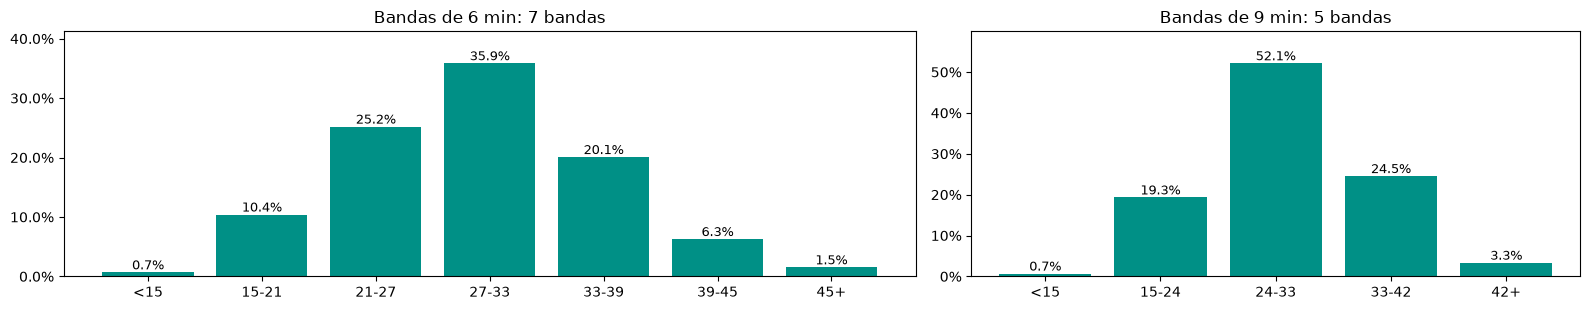

% de las partidas  partidas en train  minuto típico (mediana)
6 min <15                0.007                104                   12.658
      15-21              0.104               1586                   17.525
      21-27              0.252               3839                   24.783
      27-33              0.359               5442                   29.867
      33-39              0.201               3026                   35.267
      39-45              0.063                973                   40.867
      45+                0.015                240                   47.192
9 min <15                0.007                104                   12.658
      15-24              0.193               2941                   20.583
      24-33              0.521               7926                   28.592
      33-42              0.245               3716                   35.933
      42+                0.033                523                   44.750

In [4]:
ANCHOS = {
    "6 min": {"cortes": [0, 15, 21, 27, 33, 39, 45, np.inf],
              "bandas": ["<15", "15-21", "21-27", "27-33", "33-39", "39-45", "45+"],
              "ventana": 2},  # al jugador: las 2 bandas consecutivas más probables (12 min)
    "9 min": {"cortes": [0, 15, 24, 33, 42, np.inf],
              "bandas": ["<15", "15-24", "24-33", "33-42", "42+"],
              "ventana": 1},  # al jugador: la banda más probable (9 min)
}


def banda_de(segundos, cortes):
    """El número de banda (0 = la más corta) de una duración en segundos."""
    return pd.cut(segundos / 60, cortes, right=False, labels=False).astype(int)


for a in ANCHOS.values():
    a["K"] = len(a["bandas"])
    a["yb"], a["yb_te"] = banda_de(y10, a["cortes"]), banda_de(y10_te, a["cortes"])
    # El minuto que representa a cada banda: la mediana de la duración de sus partidas de entrenamiento
    a["minuto"] = (y10.groupby(a["yb"]).median() / 60).reindex(range(a["K"])).to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(16, 3.2), gridspec_kw={"width_ratios": [7, 5]})
resumen = {}
for ax, (ancho, a) in zip(axes, ANCHOS.items()):
    proporcion = pd.concat([a["yb"], a["yb_te"]]).value_counts(normalize=True).sort_index()
    ax.bar(a["bandas"], proporcion, color=TEAL)
    for i, v in enumerate(proporcion):
        ax.text(i, v, f"{v:.1%}", ha="center", va="bottom", fontsize=9)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
    ax.set_ylim(0, proporcion.max() * 1.15)
    ax.set_title(f"Bandas de {ancho}: {a['K']} bandas")
    resumen[ancho] = pd.DataFrame({"% de las partidas": proporcion.to_numpy(),
                                   "partidas en train": a["yb"].value_counts().sort_index().to_numpy(),
                                   "minuto típico (mediana)": a["minuto"]}, index=a["bandas"])
plt.tight_layout()
plt.show()
pd.concat(resumen).round(3)

**Las bandas están desbalanceadas en los dos anchos.**

- **6 minutos**: la banda del centro, `27-33`, tiene el **35,9 %** de las partidas, y las
  tres del medio (`21-27`, `27-33` y `33-39`) juntan el **81,2 %**. `<15` tiene el 0,7 % y
  `45+`, el 1,5 %.
- **9 minutos**: `24-33` sola tiene el **52,1 %**. `<15` tiene el 0,7 % y `42+`, el 3,3 %.

`<15` es la misma banda en los dos anchos, y tiene sólo **104 partidas de entrenamiento**.
Un modelo que conteste siempre el centro acierta mucho sin saber nada. Por eso el piso
se mide, y por eso decide el F1 macro.

**Ensanchar la banda sube el acierto de cualquier modelo, también el del piso**: con 9
minutos, contestar siempre `24-33` ya acierta la mitad. Por eso cada modelo se compara
contra **el piso de su mismo ancho**, nunca la accuracy de uno contra la del otro.

# Sección 2 · Elegir el modelo, en cada ancho

**Las métricas.** Decide el **F1 macro** (Práctica 2): el F1 de cada banda,
promediado sin pesar, así que una banda chica cuenta igual que una grande. Al lado:
la **accuracy** (banda exacta) y el **acierto a ±1 banda** (la correcta o una vecina),
que agrega el grupo porque es la lectura del jugador. **±1 banda no vale lo mismo en
los dos anchos**: con bandas de 6 minutos es la banda correcta o una vecina, unos
±6 minutos; con bandas de 9, unos ±9 minutos.

**Los modelos.** El piso, `DummyClassifier(strategy="prior")`, contesta siempre la
banda más frecuente, y como probabilidades da la frecuencia de cada banda en el
entrenamiento, iguales para todas las partidas. La regresión logística va en dos
versiones: **sin pesos**, y con **`class_weight="balanced"`**, que pesa cada partida por
la inversa de la frecuencia de su banda (Práctica 2, Parte 6). En las dos se ajusta
`C`, la inversa de la regularización: **más chico, más regularizado**. Todo se hace dos
veces, una por ancho, con los mismos cinco pedazos.

In [5]:
def a_una_banda(real, pred):
    """Proporción de partidas cuya banda predicha está a lo sumo a una de la real."""
    return np.mean(np.abs(np.asarray(real) - np.asarray(pred)) <= 1)


SCORERS = {"F1 macro": "f1_macro", "accuracy": "accuracy", "±1 banda": make_scorer(a_una_banda)}
VERSIONES = {"logística sin pesos": None, "logística balanced": "balanced"}
GRILLA_C = [0.001, 0.01, 0.1, 1, 10]
PISO = "piso (banda más frecuente)"
COLOR = {PISO: GRIS, "logística sin pesos": TEAL, "logística balanced": LADRILLO}

piso_cv, busquedas, tabla = {}, {}, {}
for ancho, a in ANCHOS.items():
    piso_cv[ancho] = cross_validate(armar(DummyClassifier(strategy="prior")), X10, a["yb"], cv=cv,
                                    scoring=SCORERS, return_train_score=True, n_jobs=-1)
    busquedas[ancho] = {n: GridSearchCV(armar(LogisticRegression(max_iter=3000, class_weight=pesos)),
                                        {"modelo__C": GRILLA_C}, cv=cv, scoring=SCORERS, refit="F1 macro",
                                        return_train_score=True, n_jobs=-1).fit(X10, a["yb"])
                        for n, pesos in VERSIONES.items()}
    filas = {PISO: {f"{m} cv": piso_cv[ancho][f"test_{m}"].mean() for m in SCORERS} |
                   {"desvío F1": piso_cv[ancho]["test_F1 macro"].std(), "C": np.nan}}
    for n, b in busquedas[ancho].items():
        i = b.best_index_
        filas[n] = {f"{m} cv": b.cv_results_[f"mean_test_{m}"][i] for m in SCORERS} | \
                   {"desvío F1": b.cv_results_["std_test_F1 macro"][i], "C": b.best_params_["modelo__C"]}
    tabla[ancho] = pd.DataFrame(filas).T[["C", "F1 macro cv", "desvío F1", "accuracy cv", "±1 banda cv"]]
pd.concat(tabla).round(3)

C  F1 macro cv  desvío F1  accuracy cv  ±1 banda cv
6 min piso (banda más frecuente)     NaN        0.075      0.001        0.358        0.809
      logística sin pesos         10.000        0.171      0.004        0.384        0.829
      logística balanced           0.001        0.171      0.004        0.202        0.508
9 min piso (banda más frecuente)     NaN        0.137      0.000        0.521        0.959
      logística sin pesos          1.000        0.214      0.007        0.534        0.955
      logística balanced           0.010        0.224      0.007        0.278        0.679

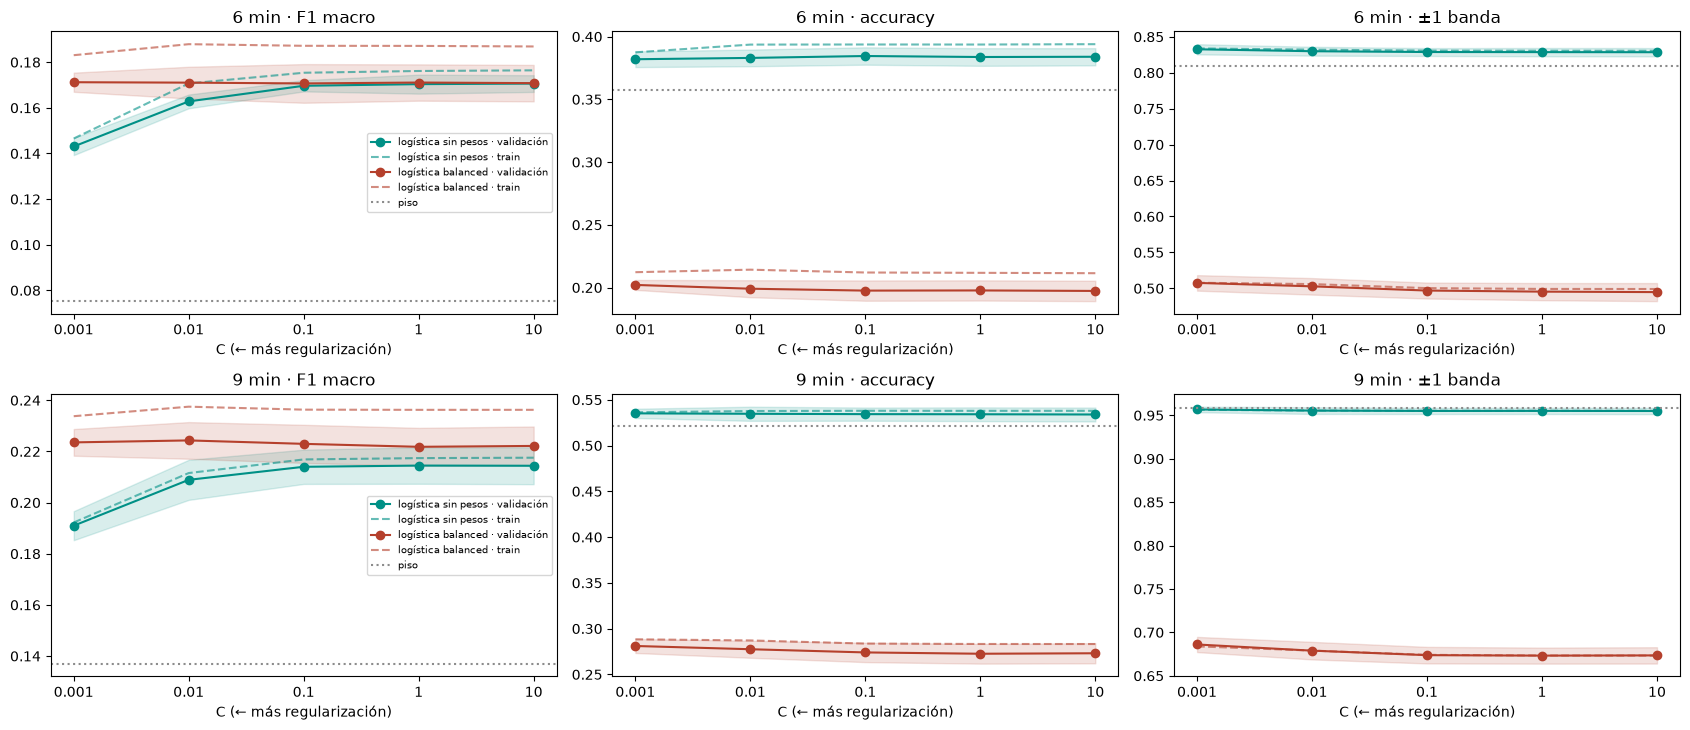

In [6]:
# La curva de C (Práctica 2, Parte 3.3): cada métrica en train y en validación, una fila por ancho
fig, axes = plt.subplots(2, 3, figsize=(17, 7.4))
for fila, ancho in zip(axes, ANCHOS):
    for ax, metrica in zip(fila, SCORERS):
        for n, b in busquedas[ancho].items():
            r, x = b.cv_results_, [str(c) for c in GRILLA_C]
            ax.plot(x, r[f"mean_test_{metrica}"], marker="o", color=COLOR[n], label=f"{n} · validación")
            ax.fill_between(x, r[f"mean_test_{metrica}"] - r[f"std_test_{metrica}"],
                            r[f"mean_test_{metrica}"] + r[f"std_test_{metrica}"], color=COLOR[n], alpha=0.15)
            ax.plot(x, r[f"mean_train_{metrica}"], linestyle="--", color=COLOR[n], alpha=0.6, label=f"{n} · train")
        ax.axhline(piso_cv[ancho][f"test_{metrica}"].mean(), color=GRIS, linestyle=":", label="piso")
        ax.set_xlabel("C (← más regularización)")
        ax.set_title(f"{ancho} · {metrica}")
    fila[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

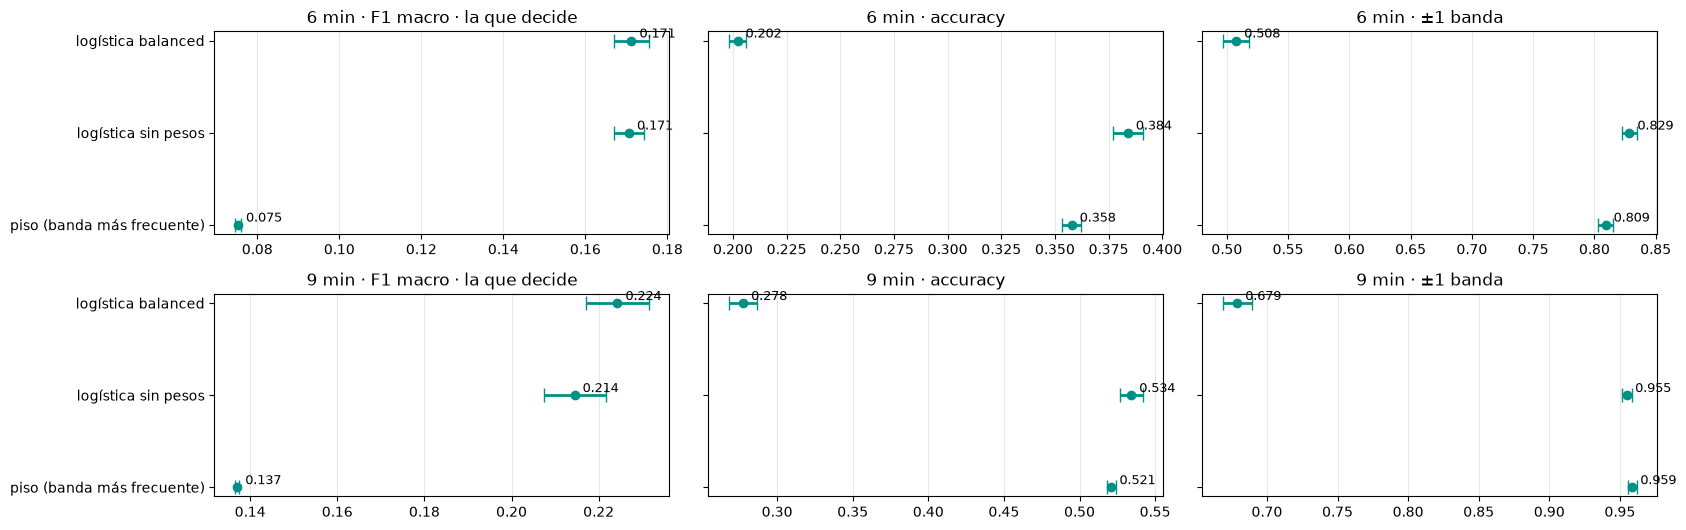

In [7]:
# La comparación con barra de error (Práctica 2, Parte 2.2): media ± desvío entre los cinco pedazos
fig, axes = plt.subplots(2, 3, figsize=(17, 5.4))
for fila, ancho in zip(axes, ANCHOS):
    desvios = {PISO: {m: piso_cv[ancho][f"test_{m}"].std() for m in SCORERS}} | \
              {n: {m: b.cv_results_[f"std_test_{m}"][b.best_index_] for m in SCORERS}
               for n, b in busquedas[ancho].items()}
    for ax, metrica in zip(fila, SCORERS):
        medias = tabla[ancho][f"{metrica} cv"]
        ax.errorbar(medias, medias.index, xerr=[desvios[n][metrica] for n in medias.index], fmt="o",
                    color=TEAL, ecolor=TEAL, elinewidth=2, capsize=5)
        for n, v in medias.items():
            ax.text(v, n, f"  {v:.3f}", va="bottom", fontsize=9)
        ax.set_title(f"{ancho} · {metrica}" + (" · la que decide" if metrica == "F1 macro" else ""))
        ax.grid(axis="x", alpha=0.3)
        if metrica != "F1 macro":
            ax.set_yticklabels([])
plt.tight_layout()
plt.show()

In [8]:
# La regla de la cátedra: la versión con pesos (la más compleja) gana sólo si supera a la sin pesos
# en F1 macro por más que su desvío. Si no, queda la sin pesos
regla = {}
for ancho, t in tabla.items():
    sin, bal = t.loc["logística sin pesos"], t.loc["logística balanced"]
    diferencia = bal["F1 macro cv"] - sin["F1 macro cv"]
    elige = "logística balanced" if diferencia > bal["desvío F1"] else "logística sin pesos"
    regla[ancho] = {"F1 sin pesos": round(sin["F1 macro cv"], 4), "F1 balanced": round(bal["F1 macro cv"], 4),
                    "balanced − sin pesos": round(diferencia, 4), "desvío de balanced": round(bal["desvío F1"], 4),
                    "la regla elige": f"{elige} (C={t.loc[elige, 'C']:g})"}
# Decisión del grupo: el modelo final de los dos anchos es la logística sin pesos. Con 9 minutos la regla elige
# la balanced, pero el grupo la descarta: queda por debajo del piso en accuracy, en minutos y en calibración
final = {ancho: "logística sin pesos" for ancho in ANCHOS}
for ancho in ANCHOS:
    regla[ancho]["modelo final (grupo)"] = f"{final[ancho]} (C={tabla[ancho].loc[final[ancho], 'C']:g})"
pd.DataFrame(regla).T

,F1 sin pesos,F1 balanced,balanced − sin pesos,desvío de balanced,la regla elige,modelo final (grupo)
6 min,0.1706,0.1712,0.0006,0.0042,logística sin pesos (C=10),logística sin pesos (C=10)
9 min,0.2145,0.2243,0.0098,0.0072,logística balanced (C=0.01),logística sin pesos (C=1)


**Con 6 minutos, la regla elige la sin pesos.** Las dos versiones empatan en F1 macro:
sin pesos (`C=10`) **0,171 ± 0,004**, balanced (`C=0,001`) 0,171 ± 0,004. La balanced le gana
por 0,0006, mucho menos que su desvío. En lo demás gana la sin pesos: accuracy 38,4 %
contra 20,2 %, y ±1 banda 82,9 % contra 50,8 %. El piso: F1 0,075, accuracy 35,8 % y ±1 banda
80,9 %.

**Con 9 minutos, la regla elige la balanced, y el grupo la descarta.** La balanced
(`C=0,01`) da F1 macro **0,224 ± 0,007**, y la sin pesos (`C=1`), **0,214 ± 0,007**. La
diferencia, 0,0098, supera el desvío (0,0072), así que por la regla gana la balanced. Pero
gana sólo en F1 macro, y lo hace contestando las bandas de las puntas cientos de veces
(Sección 4). En todo lo demás queda por debajo del piso: accuracy **27,8 %** contra 52,1 %
del piso y 53,4 % de la sin pesos, y ±1 banda 67,9 % contra 95,9 % y 95,5 %. En el test
(Secciones 3 a 5) el F1 empata, el error en minutos casi se duplica y las probabilidades
dejan de ser creíbles. **Decisión del grupo: el modelo final de 9 minutos también es la
sin pesos**, como en la versión de 3 minutos, donde `balanced` también se había descartado.

**La curva de C dice que la regularización casi no importa.** Para la sin pesos, entre
`C=0,1` y `C=10` las curvas de los dos anchos son planas, y el F1 sólo cae con `C=0,01` y
`C=0,001`. Que en 6 minutos gane `C=10`, el borde de la grilla, no cambia nada: entre 0,1 y
10 el F1 se mueve en milésimas. Las líneas de train y validación de la sin pesos casi se
tocan: **no sobreajusta**.

# Sección 3 · El test, una sola vez

Además de las métricas de clasificación, se mide el error **en minutos**: cada
banda se representa con la mediana de la duración de sus partidas de entrenamiento,
y se cuenta en qué porcentaje de las partidas la banda predicha queda a menos de 3 y
de 5 minutos de lo real.

In [9]:
piso_final, modelos, pred, proba, error_min = {}, {}, {}, {}, {}
for ancho, a in ANCHOS.items():
    piso_final[ancho] = armar(DummyClassifier(strategy="prior")).fit(X10, a["yb"])
    modelos[ancho] = {n: b.best_estimator_ for n, b in busquedas[ancho].items()}
    todos = {PISO: piso_final[ancho]} | modelos[ancho]
    pred[ancho] = {n: pd.Series(m.predict(X10_te), index=te) for n, m in todos.items()}
    proba[ancho] = {n: pd.DataFrame(m.predict_proba(X10_te), index=te, columns=a["bandas"]) for n, m in todos.items()}
    error_min[ancho] = {n: pd.Series(a["minuto"][p], index=te) - y10_te / 60 for n, p in pred[ancho].items()}


def metricas(ancho, real, p, n):
    """Las métricas de clasificación y las del error en minutos."""
    e = error_min[ancho][n].loc[real.index].abs()
    return {"F1 macro": f1_score(real, p, average="macro", labels=range(ANCHOS[ancho]["K"]), zero_division=0),
            "accuracy": accuracy_score(real, p), "±1 banda": a_una_banda(real, p),
            "error ≤ 3 min": (e <= 3).mean(), "error ≤ 5 min": (e <= 5).mean(), "error medio (min)": e.mean()}


test = pd.concat({ancho: pd.DataFrame({n: metricas(ancho, a["yb_te"], p, n) for n, p in pred[ancho].items()}).T
                  for ancho, a in ANCHOS.items()})
test.round(3)

F1 macro  accuracy  ±1 banda  error ≤ 3 min  error ≤ 5 min  error medio (min)
6 min piso (banda más frecuente)     0.076     0.362     0.820          0.365          0.577              5.306
      logística sin pesos            0.159     0.369     0.843          0.375          0.591              5.145
      logística balanced             0.160     0.189     0.502          0.210          0.316              9.837
9 min piso (banda más frecuente)     0.137     0.522     0.964          0.370          0.570              5.321
      logística sin pesos            0.221     0.544     0.962          0.380          0.581              5.151
      logística balanced             0.218     0.273     0.675          0.206          0.330              9.498

**Los dos modelos finales en el test** (los dos son la logística sin pesos):

| | 6 minutos (`C=10`) | piso 6 min | 9 minutos (`C=1`) | piso 9 min |
|---|---|---|---|---|
| F1 macro | **0,159** | 0,076 | **0,221** | 0,137 |
| accuracy | 36,9 % | 36,2 % | 54,4 % | 52,2 % |
| ±1 banda | 84,3 % (±6 min) | 82,0 % | 96,2 % (±9 min) | 96,4 % |
| error ≤ 3 min | 37,5 % | 36,5 % | 38,0 % | 37,0 % |
| error medio | 5,15 min | 5,31 min | 5,15 min | 5,32 min |

El F1 del test queda en línea con la validación: 0,159 contra 0,171 con 6 minutos, y 0,221
contra 0,214 con 9.

**Hay que decirlo con todas las letras: en minutos, la logística casi no le gana al
piso, con ninguno de los dos anchos.** El 37,5 % y el 38,0 % de las partidas quedan a menos
de 3 minutos de lo real, contra el 36,5 % y el 37,0 % del piso, y el error medio baja de
5,3 a 5,15 minutos. **Ensanchar la banda no cambia el error en minutos**: lo que sube con 9
minutos es la accuracy, porque la banda es más ancha, no porque el modelo sepa más. Con 9
minutos, el ±1 banda queda incluso dos décimas debajo del piso: con cinco bandas, casi
cualquier respuesta del centro está a una banda de lo real.

La balanced, que se descartó, en el test: F1 0,160 y 0,218, accuracy **18,9 %** y **27,3 %**,
y un error medio de **9,8** y **9,5 minutos**, casi el doble que el piso. Lo que la logística
agrega no está en la banda que contesta, sino en las **probabilidades** (Sección 5).

# Sección 4 · Dónde se equivoca

El análisis del error, como en la Práctica 1 (4.3, «la accuracy no alcanza»): la
matriz de confusión, las métricas de cada banda, el error en bandas y el error por
grupo de elo. Para cada ancho, las dos versiones de la logística.

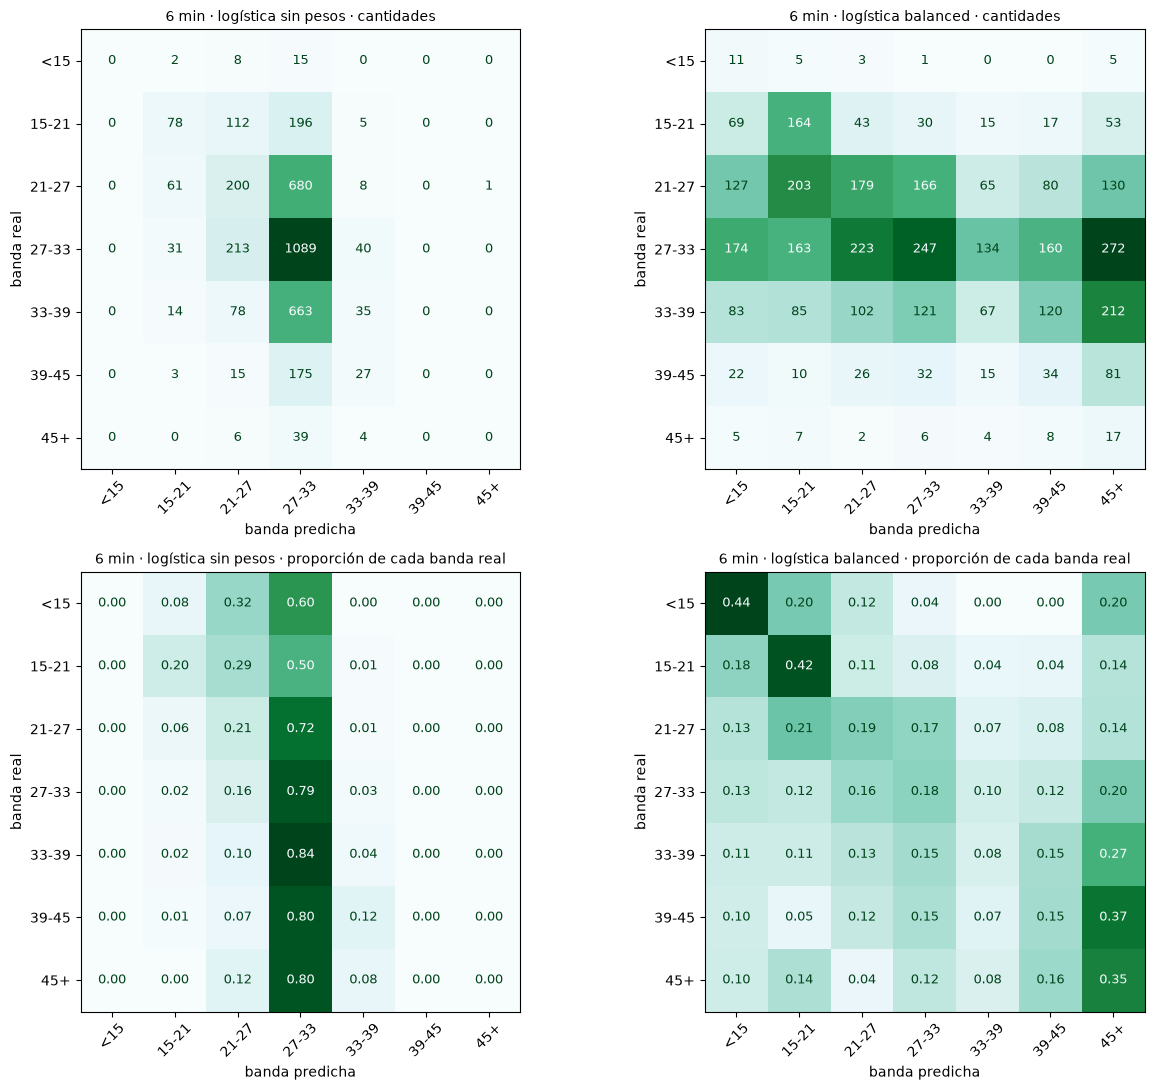

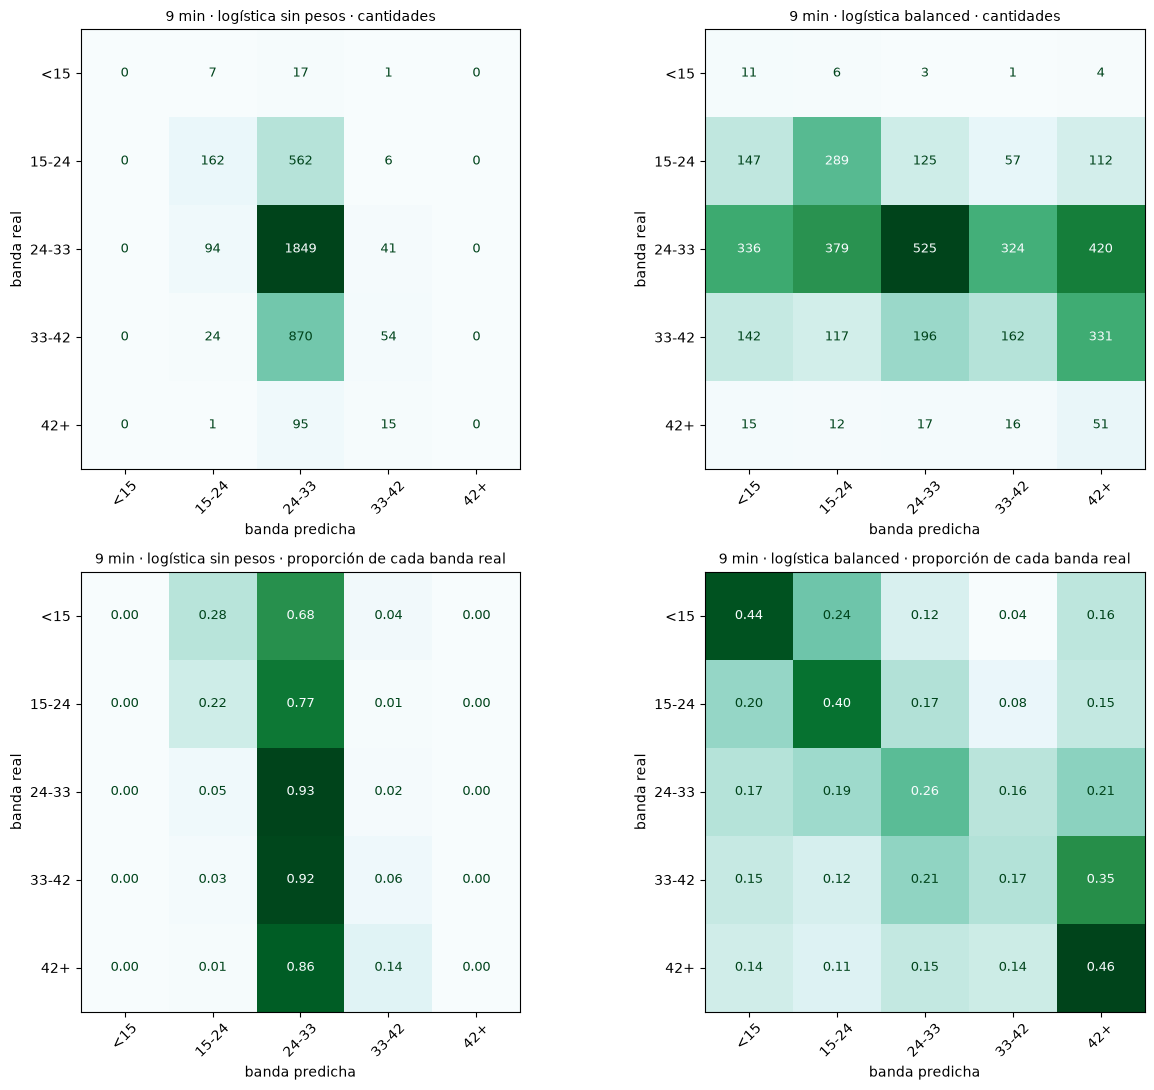

In [10]:
# 4.1 · Las matrices de confusión: cantidades arriba, y normalizadas por fila abajo (de cada banda real, a dónde va)
for ancho, a in ANCHOS.items():
    fig, axes = plt.subplots(2, 2, figsize=(13, 11))
    for col, n in enumerate(modelos[ancho]):
        for fila, (normalizar, formato) in enumerate([(None, "d"), ("true", ".2f")]):
            ax = axes[fila, col]
            ConfusionMatrixDisplay.from_predictions(a["yb_te"], pred[ancho][n], labels=range(a["K"]),
                                                    display_labels=a["bandas"], normalize=normalizar,
                                                    values_format=formato, cmap="BuGn", colorbar=False, ax=ax,
                                                    text_kw={"fontsize": 9})
            ax.set_title(f"{ancho} · {n} · {'cantidades' if normalizar is None else 'proporción de cada banda real'}",
                         fontsize=10)
            ax.set_xlabel("banda predicha")
            ax.set_ylabel("banda real")
            ax.tick_params(axis="x", rotation=45)
    plt.tight_layout()
    plt.show()

**La sin pesos contesta casi siempre el centro, en los dos anchos.**

- **6 minutos**: contesta `27-33` en **2.857 de las 3.798 partidas (75,2 %)** y `21-27` en
  632 (16,6 %). **Nunca contesta `<15` ni `39-45`**, y `45+` una sola vez, mal. De cada banda
  real desde `21-27` hasta `45+`, entre el 72 y el 84 % de las partidas termina predicha
  como `27-33`.
- **9 minutos**: contesta `24-33` en **3.393 partidas (89,3 %)**. **Nunca contesta `<15` ni
  `42+`**. Las de `33-42` van a `24-33` en el 92 % de los casos.

**La única banda fuera del centro que ve venir es la corta**: `15-21` acierta 78 de 391
(20 %) y `15-24`, 162 de 730 (22 %). Es la banda de la rendición (Entrega 2).

**La balanced se reparte por toda la matriz.** Con 6 minutos acierta 17 de las 49 partidas
de `45+`, pero contesta `45+` **770 veces**. Con 9 minutos acierta 51 de las 111 de `42+`, y
contesta `42+` **918 veces**. Es lo que le sube el F1 macro: recall en las puntas, pagado
con todo lo demás.

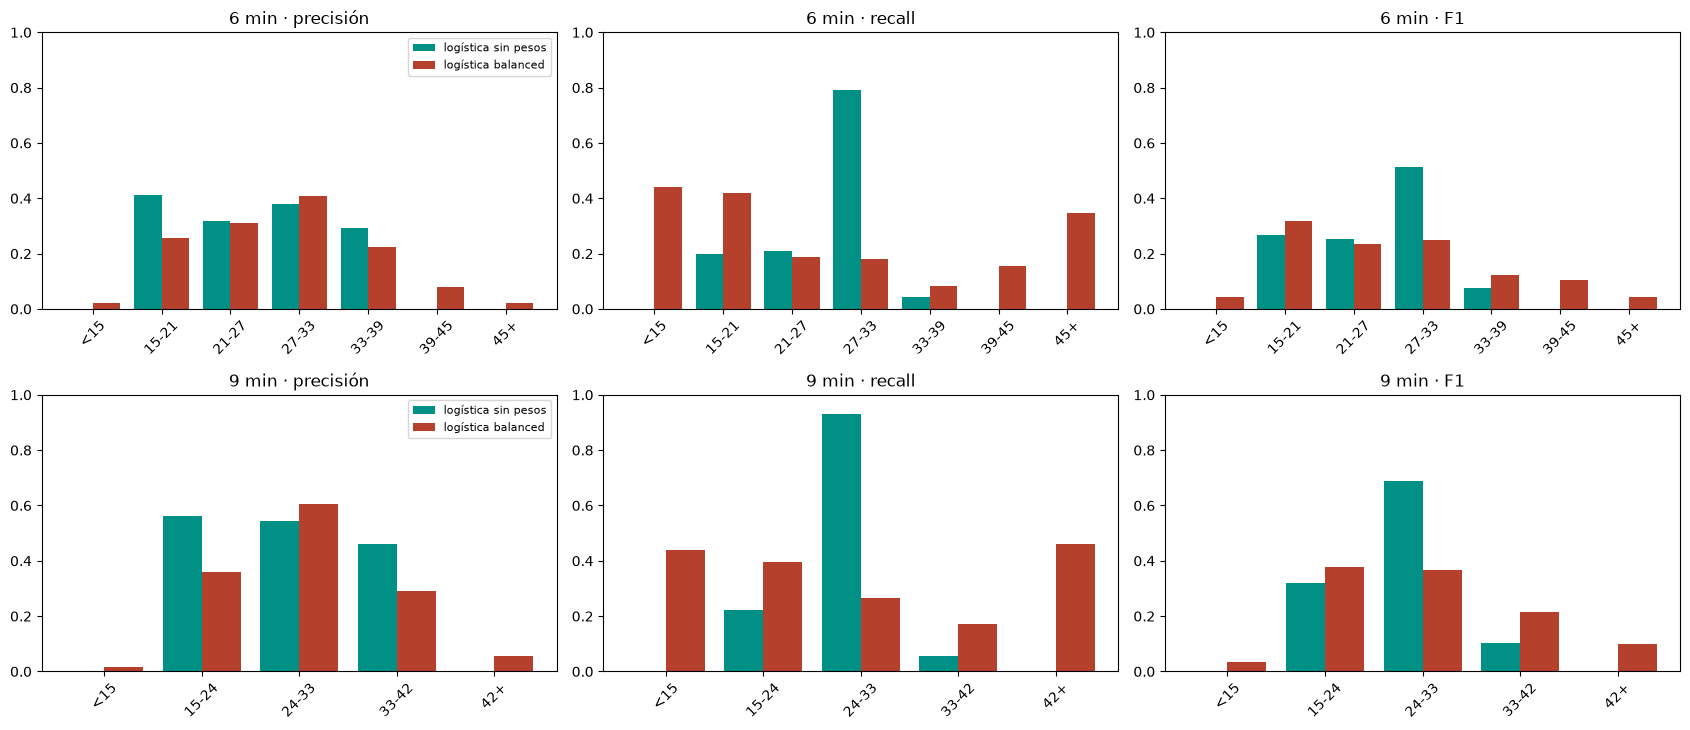

logística sin pesos                       logística balanced                      
                      precisión recall    F1 partidas          precisión recall    F1 partidas
6 min <15                  0.00   0.00  0.00       25               0.02   0.44  0.04       25
      15-21                0.41   0.20  0.27      391               0.26   0.42  0.32      391
      21-27                0.32   0.21  0.25      950               0.31   0.19  0.23      950
      27-33                0.38   0.79  0.51     1373               0.41   0.18  0.25     1373
      33-39                0.29   0.04  0.08      790               0.22   0.08  0.12      790
      39-45                0.00   0.00  0.00      220               0.08   0.15  0.11      220
      45+                  0.00   0.00  0.00       49               0.02   0.35  0.04       49
9 min <15                  0.00   0.00  0.00       25               0.02   0.44  0.03       25
      15-24                0.56   0.22  0.32      730               0.36   0.40  0.38      730
      24-33                0.54   0.93  0.69     1984               0.61   0.26  0.37     1984
      33-42                0.46   0.06  0.10      948               0.29   0.17  0.21      948
      42+                  0.00   0.00  0.00      111               0.06   0.46  0.10      111

In [11]:
# 4.2 · Precisión, recall y F1 de cada banda (el classification_report, dibujado), una fila por ancho
fig, axes = plt.subplots(2, 3, figsize=(17, 7.4))
reporte = {}
for fila, (ancho, a) in zip(axes, ANCHOS.items()):
    for n, desp in zip(modelos[ancho], [-0.2, 0.2]):
        p, r, f, s = precision_recall_fscore_support(a["yb_te"], pred[ancho][n], labels=range(a["K"]), zero_division=0)
        reporte[(ancho, n)] = pd.DataFrame({"precisión": p, "recall": r, "F1": f, "partidas": s}, index=a["bandas"])
        for ax, m in zip(fila, ["precisión", "recall", "F1"]):
            ax.bar(np.arange(a["K"]) + desp, reporte[(ancho, n)][m], 0.4, color=COLOR[n], label=n)
    for ax, m in zip(fila, ["precisión", "recall", "F1"]):
        ax.set_xticks(range(a["K"]), a["bandas"], rotation=45)
        ax.set_ylim(0, 1)
        ax.set_title(f"{ancho} · {m}")
    fila[0].legend(fontsize=8)
plt.tight_layout()
plt.show()
pd.concat({ancho: pd.concat({n: reporte[(ancho, n)] for n in modelos[ancho]}, axis=1) for ancho in ANCHOS}).round(2)

**Por banda, la sin pesos sólo funciona en el centro y en la banda corta.**

- **6 minutos**: su mejor F1 está en `27-33` (**0,51**, con recall 0,79), después `15-21`
  (0,27) y `21-27` (0,25). `33-39` llega a 0,08. En `<15`, `39-45` y `45+` el F1 es cero.
- **9 minutos**: `24-33` da **0,69** (recall 0,93), `15-24` 0,32 (con precisión 0,56: cuando
  la contesta, acierta más de la mitad de las veces) y `33-42` 0,10. En `<15` y `42+`, cero.

**La balanced cambia recall por precisión.** En las puntas sube el recall: `<15` pasa de 0 a
0,44 en los dos anchos, `45+` a 0,35 y `42+` a 0,46. Pero la precisión es de 0,02 a 0,06: con 9 minutos,
acierta una de cada dieciocho veces que dice `42+`. Y en el centro el recall se derrumba: en
`27-33`, de 0,79 a 0,18; en `24-33`, de 0,93 a 0,26.

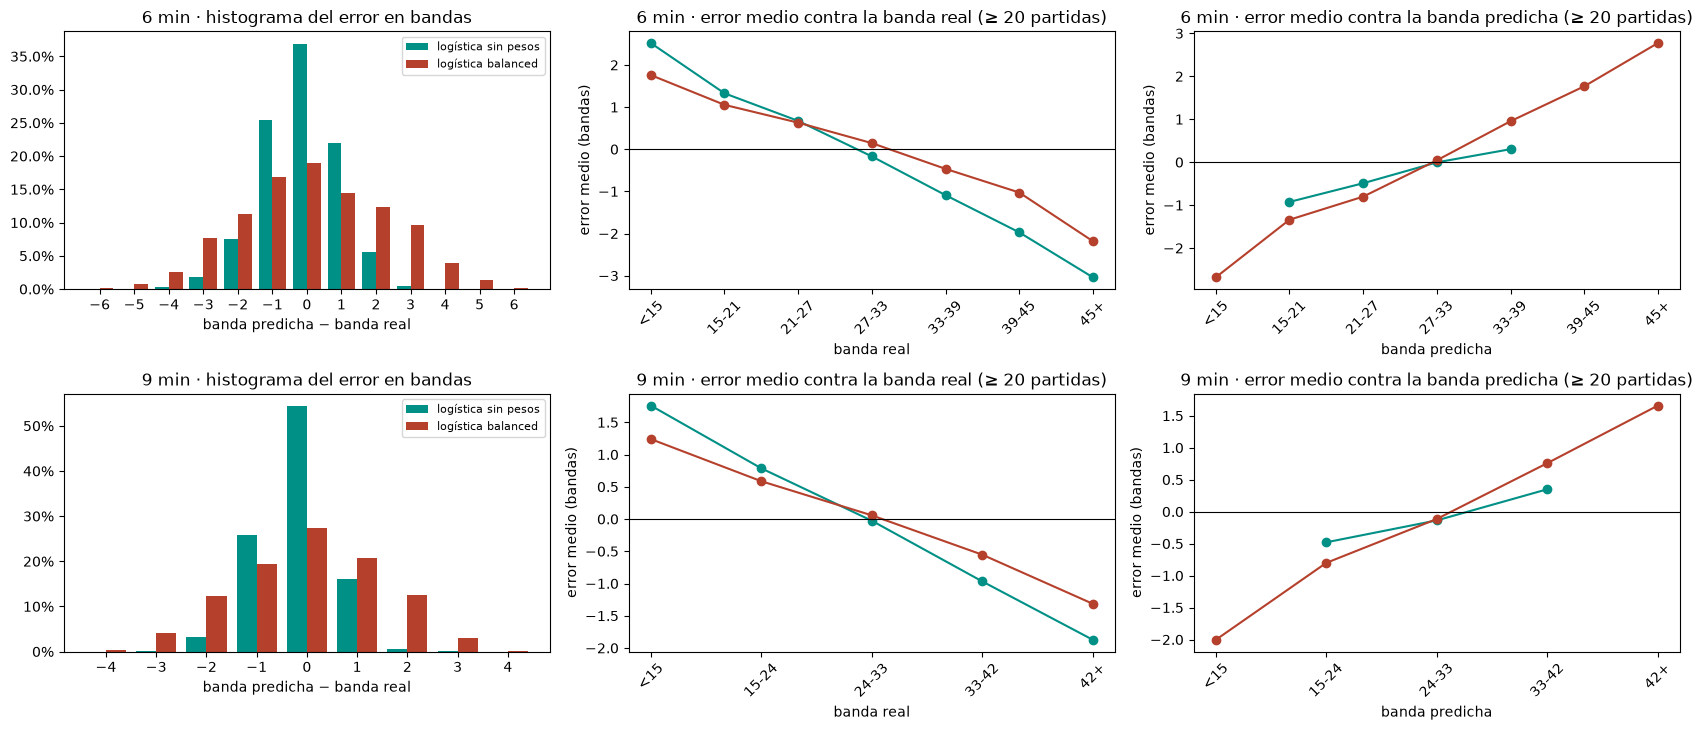

banda exacta  a 1 banda  a 2 bandas  a 3 o más  error medio (bandas)
6 min logística sin pesos         0.369      0.473       0.132      0.026                -0.121
      logística balanced          0.189      0.313       0.236      0.261                 0.146
9 min logística sin pesos         0.544      0.418       0.037      0.001                -0.148
      logística balanced          0.273      0.401       0.250      0.075                -0.026

In [12]:
# 4.3 · El error en bandas (predicha − real): su histograma, y su media contra la banda real y contra la predicha
error_banda = {ancho: {n: pred[ancho][n] - a["yb_te"] for n in modelos[ancho]} for ancho, a in ANCHOS.items()}
fig, axes = plt.subplots(2, 3, figsize=(17, 7.4))
for fila, (ancho, a) in zip(axes, ANCHOS.items()):
    K = a["K"]
    for (n, e), desp in zip(error_banda[ancho].items(), [-0.2, 0.2]):
        frec = e.value_counts(normalize=True).reindex(range(-K + 1, K), fill_value=0)
        fila[0].bar(frec.index + desp, frec, 0.4, color=COLOR[n], label=n)
        for ax, ref in zip(fila[1:], [a["yb_te"], pred[ancho][n]]):
            medio = e.groupby(ref).agg(["mean", "size"])
            medio = medio[medio["size"] >= 20]
            ax.plot(medio.index, medio["mean"], marker="o", color=COLOR[n], label=n)
    fila[0].set_xticks(range(-K + 1, K))
    fila[0].set_xlabel("banda predicha − banda real")
    fila[0].yaxis.set_major_formatter(mtick.PercentFormatter(1))
    fila[0].set_title(f"{ancho} · histograma del error en bandas")
    fila[0].legend(fontsize=8)
    for ax, eje in zip(fila[1:], ["real", "predicha"]):
        ax.axhline(0, color="black", linewidth=0.8)
        ax.set_xlabel(f"banda {eje}")
        ax.set_ylabel("error medio (bandas)")
        ax.set_title(f"{ancho} · error medio contra la banda {eje} (≥ 20 partidas)")
        ax.set_xticks(range(K), a["bandas"], rotation=45)
plt.tight_layout()
plt.show()
pd.concat({ancho: pd.DataFrame({n: {"banda exacta": (e == 0).mean(), "a 1 banda": (e.abs() == 1).mean(),
                                    "a 2 bandas": (e.abs() == 2).mean(), "a 3 o más": (e.abs() >= 3).mean(),
                                    "error medio (bandas)": e.mean()} for n, e in eb.items()}).T
           for ancho, eb in error_banda.items()}).round(3)

**La sin pesos erra cerca.**

- **6 minutos**: banda exacta en el **36,9 %** de las partidas, y a una banda en el
  **47,3 %**: el 84,2 % queda a un paso o menos. A tres bandas o más, el **2,6 %**.
- **9 minutos**: banda exacta en el **54,4 %**, y a una banda en el 41,8 %: el 96,2 %. A
  tres bandas o más, el 0,1 %.

La balanced: exacta en el 18,9 % y el 27,3 %, y a tres bandas o más en el **26,1 %** y el
7,5 %.

**Contra la banda real, el error es una recta que baja**: la sin pesos predice las
partidas de `<15` unas dos bandas y media más largas con 6 minutos (casi dos con 9), y las
de la banda más larga, unas tres bandas más cortas con 6 minutos (casi dos con 9). Es la
tendencia al centro de un modelo con poca señal. **Contra la banda predicha, la sin pesos
queda cerca de cero**: cuando dice `27-33` o `24-33`, la partida termina en promedio ahí.
La balanced se aleja en las puntas: cuando dice `45+`, la partida termina en promedio
casi tres bandas antes.

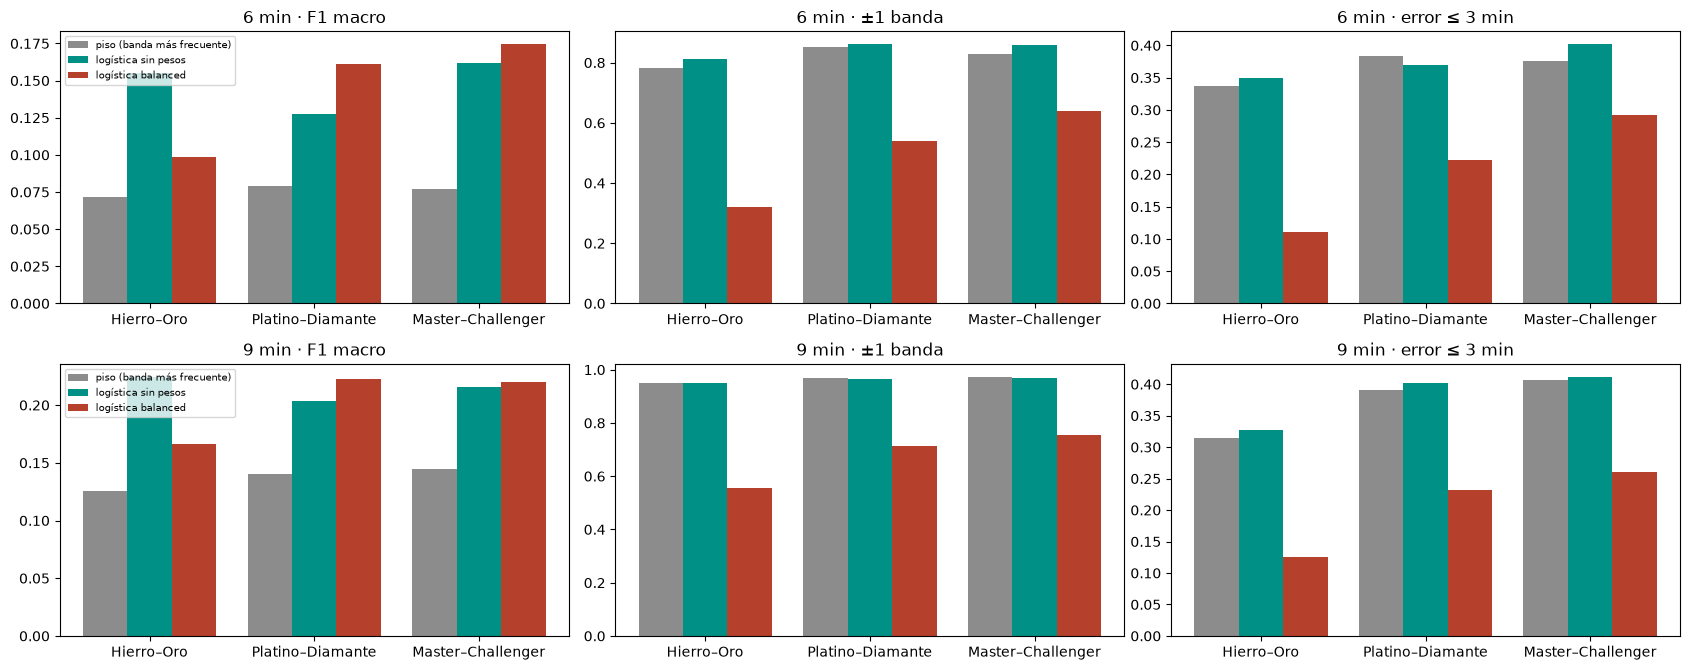

F1 macro  accuracy  ±1 banda  error ≤ 3 min
6 min Hierro–Oro        piso (banda más frecuente)     0.072     0.335     0.781          0.338
                        logística sin pesos            0.155     0.349     0.811          0.350
                        logística balanced             0.098     0.094     0.321          0.111
      Platino–Diamante  piso (banda más frecuente)     0.079     0.385     0.852          0.384
                        logística sin pesos            0.128     0.361     0.861          0.370
                        logística balanced             0.161     0.200     0.540          0.222
      Master–Challenger piso (banda más frecuente)     0.077     0.367     0.829          0.377
                        logística sin pesos            0.162     0.394     0.857          0.402
                        logística balanced             0.174     0.270     0.640          0.292
9 min Hierro–Oro        piso (banda más frecuente)     0.126     0.457     0.951          0.315
                        logística sin pesos            0.225     0.482     0.951          0.328
                        logística balanced             0.166     0.169     0.555          0.126
      Platino–Diamante  piso (banda más frecuente)     0.141     0.543     0.968          0.390
                        logística sin pesos            0.203     0.560     0.966          0.402
                        logística balanced             0.222     0.294     0.713          0.231
      Master–Challenger piso (banda más frecuente)     0.145     0.567     0.973          0.406
                        logística sin pesos            0.216     0.588     0.969          0.412
                        logística balanced             0.220     0.353     0.755          0.261

In [13]:
# 4.4 · Por grupo de elo
por_grupo = pd.concat({(ancho, g): pd.DataFrame({n: metricas(ancho, a["yb_te"][grupo_te == g], p[grupo_te == g], n)
                                                 for n, p in pred[ancho].items()}).T
                       for ancho, a in ANCHOS.items() for g in GRUPOS})
fig, axes = plt.subplots(2, 3, figsize=(17, 6.8))
for fila, ancho in zip(axes, ANCHOS):
    for ax, m in zip(fila, ["F1 macro", "±1 banda", "error ≤ 3 min"]):
        for i, n in enumerate(pred[ancho]):
            ax.bar(np.arange(3) + (i - 1) * 0.27, [por_grupo.loc[(ancho, g, n), m] for g in GRUPOS], 0.27,
                   color=COLOR[n], label=n)
        ax.set_xticks(range(3), GRUPOS)
        ax.set_title(f"{ancho} · {m}")
    fila[0].legend(fontsize=7, loc="upper left")
plt.tight_layout()
plt.show()
por_grupo[["F1 macro", "accuracy", "±1 banda", "error ≤ 3 min"]].round(3)

**Por grupo de elo, la sin pesos le gana al piso en F1 en los tres grupos**, y en lo demás
la diferencia es chica:

- **6 minutos**: en ±1 banda, Hierro–Oro pasa de 78,1 % (piso) a **81,1 %**, Platino–Diamante
  de 85,2 a 86,1 % y Master–Challenger de 82,9 a **85,7 %**. A menos de 3 minutos, gana en
  Hierro–Oro (35,0 contra 33,8 %) y en Master–Challenger (40,2 contra 37,7 %), y pierde en
  Platino–Diamante (37,0 contra 38,4 %).
- **9 minutos**: la accuracy sube unos dos puntos en cada grupo (45,7 → 48,2 %, 54,3 → 56,0 % y
  56,7 → 58,8 %). En ±1 banda empata con el piso (de 95 a 97 % en todos).

La balanced queda lejos del piso en los tres grupos y con los dos anchos.

# Sección 5 · Lo que le sirve al jugador

La razón para elegir la logística es que da **una probabilidad para cada banda**.
Eso sirve sólo si las probabilidades son **creíbles**: si cuando el modelo dice 60 %,
pasa más o menos el 60 % de las veces. Esta sección lo mide.

**Qué se le muestra al jugador** depende del ancho:

- con **6 minutos**, la **ventana de 2 bandas** consecutivas más probable (12 minutos) y
  su probabilidad sumada;
- con **9 minutos**, **la banda más probable** (9 minutos) y su probabilidad.

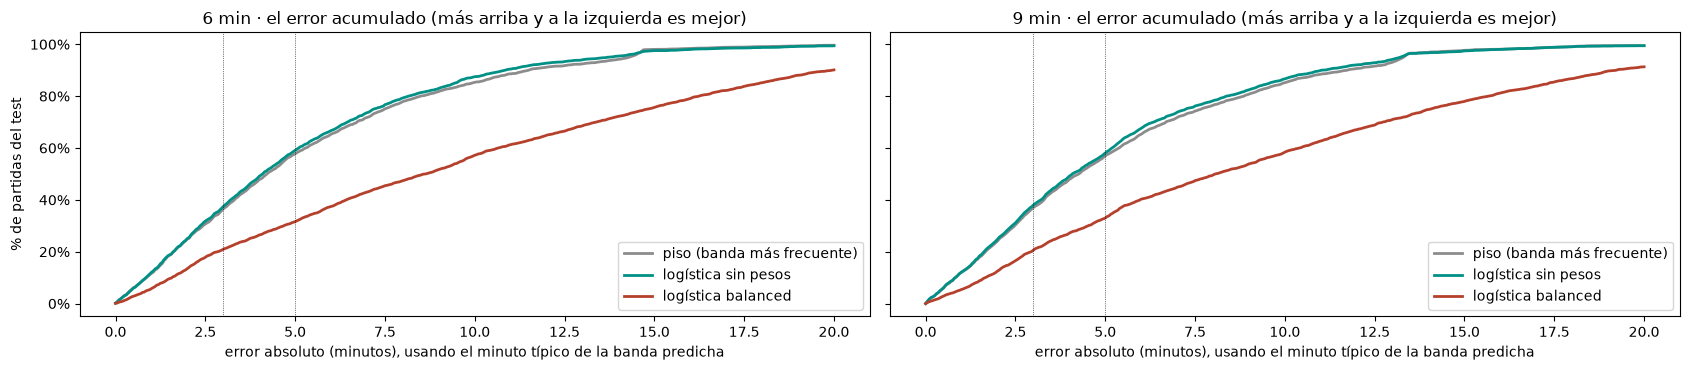

In [14]:
# 5.1 · El error acumulado en minutos: qué porcentaje de las partidas queda a menos de t minutos de lo real
t = np.linspace(0, 20, 401)
fig, axes = plt.subplots(1, 2, figsize=(17, 3.8), sharey=True)
for ax, ancho in zip(axes, ANCHOS):
    for n, e in error_min[ancho].items():
        ax.plot(t, [(e.abs() <= u).mean() for u in t], color=COLOR[n], linewidth=2, label=n)
    for u in [3, 5]:
        ax.axvline(u, color="black", linewidth=0.5, linestyle=":")
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
    ax.set_xlabel("error absoluto (minutos), usando el minuto típico de la banda predicha")
    ax.set_title(f"{ancho} · el error acumulado (más arriba y a la izquierda es mejor)")
    ax.legend()
axes[0].set_ylabel("% de partidas del test")
plt.tight_layout()
plt.show()

**Las curvas de la sin pesos y del piso casi se superponen**, con los dos anchos, y la de la
balanced queda muy abajo. Las curvas de 6 y de 9 minutos son casi iguales. Contestar una
sola banda, en minutos, no es mejor que contestar siempre el centro. Por eso la utilidad
hay que buscarla en las probabilidades.

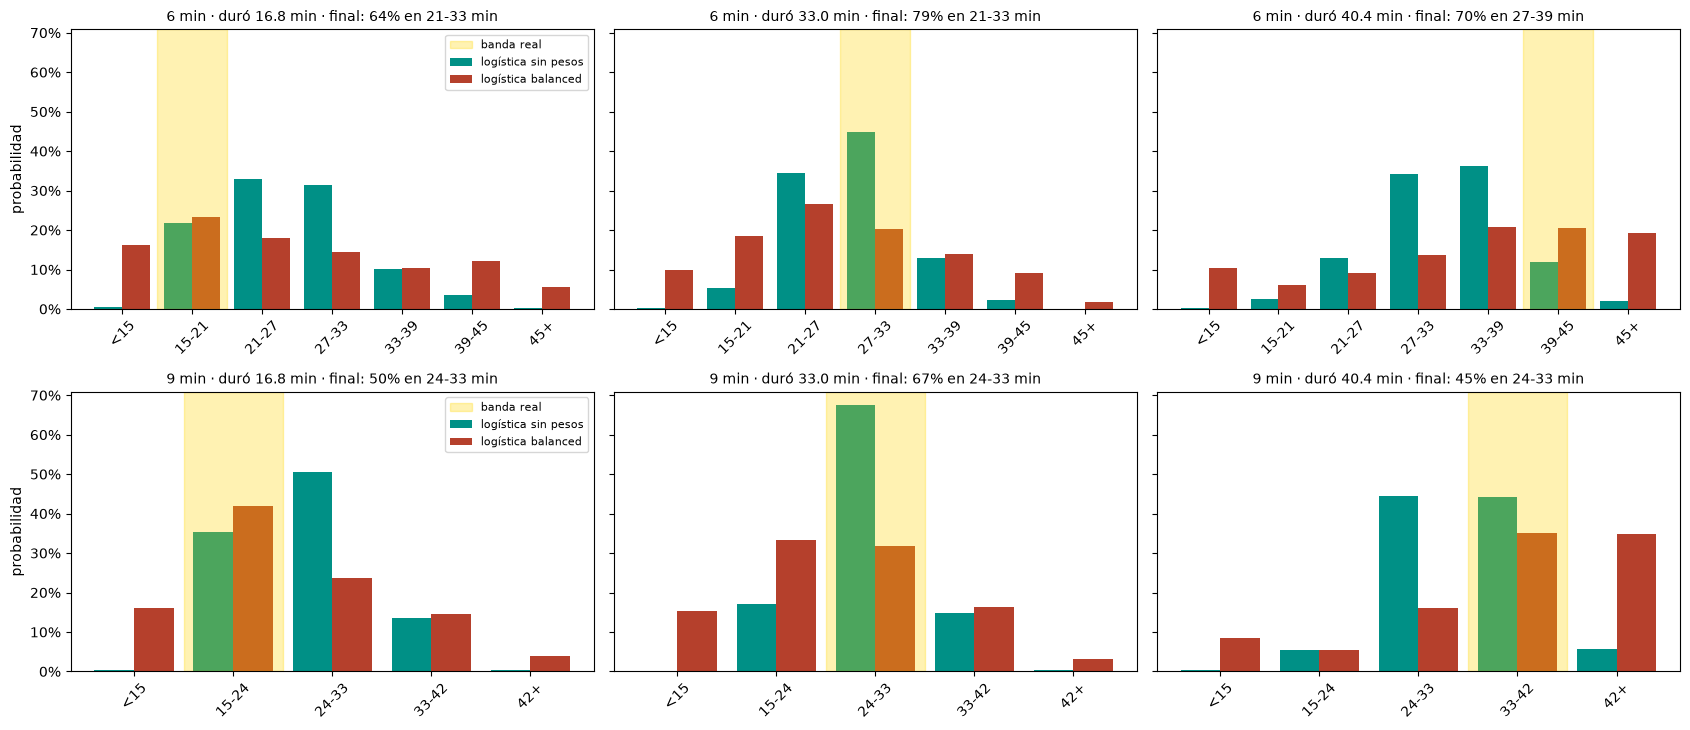

ventana probabilidad banda real
6 min 16.8 min  21-33 min     0.642659      15-21
      33.0 min  21-33 min     0.792801      27-33
      40.4 min  27-39 min     0.704487      39-45
9 min 16.8 min  24-33 min     0.504878      15-24
      33.0 min  24-33 min     0.674884      24-33
      40.4 min  24-33 min     0.445177      33-42

In [15]:
# 5.2 · Lo que vería el jugador: las probabilidades por banda de tres partidas del test, una corta, una media y una larga
def rango(bandas, i, j):
    """El texto de la ventana que va de la banda i a la j."""
    ini, fin = bandas[i], bandas[j]
    if i == j:
        return f"{ini} min"
    if ini.startswith("<"):
        return f"<{fin.split('-')[-1]} min"
    if fin.endswith("+"):
        return f"{ini.split('-')[0]}+ min"
    return f"{ini.split('-')[0]}-{fin.split('-')[-1]} min"


def sumas_ventana(P, n):
    """Para cada partida (fila de P), la probabilidad sumada de cada ventana de n bandas consecutivas."""
    return np.stack([P[:, i:i + n].sum(axis=1) for i in range(P.shape[1] - n + 1)], axis=1)


def ventana(p, ancho):
    """Lo que se le muestra al jugador: la ventana más probable y su probabilidad."""
    a = ANCHOS[ancho]
    s = sumas_ventana(p.to_numpy()[None, :], a["ventana"])[0]
    i = int(s.argmax())
    return rango(a["bandas"], i, i + a["ventana"] - 1), s[i]


# Las mismas tres partidas para los dos anchos: una de 15-21, una de 27-33 y una de 39-45 minutos
seis = ANCHOS["6 min"]["yb_te"]
ejemplos = [seis[seis == b].sample(1, random_state=SEMILLA).index[0] for b in [1, 3, 5]]
fig, axes = plt.subplots(2, 3, figsize=(17, 7.4), sharey=True)
for fila, (ancho, a) in zip(axes, ANCHOS.items()):
    for ax, i in zip(fila, ejemplos):
        for n, desp in zip(modelos[ancho], [-0.2, 0.2]):
            ax.bar(np.arange(a["K"]) + desp, proba[ancho][n].loc[i], 0.4, color=COLOR[n], label=n)
        ax.axvspan(a["yb_te"][i] - 0.5, a["yb_te"][i] + 0.5, color="gold", alpha=0.3, label="banda real")
        texto, prob = ventana(proba[ancho][final[ancho]].loc[i], ancho)
        ax.set_title(f"{ancho} · duró {y10_te[i] / 60:.1f} min · final: {prob:.0%} en {texto}", fontsize=10)
        ax.set_xticks(range(a["K"]), a["bandas"], rotation=45)
    fila[0].yaxis.set_major_formatter(mtick.PercentFormatter(1))
    fila[0].set_ylabel("probabilidad")
    fila[0].legend(fontsize=8)
plt.tight_layout()
plt.show()
pd.DataFrame({(ancho, f"{y10_te[i] / 60:.1f} min"): dict(zip(["ventana", "probabilidad"], ventana(proba[ancho][final[ancho]].loc[i], ancho)))
              | {"banda real": ANCHOS[ancho]["bandas"][ANCHOS[ancho]["yb_te"][i]]}
              for ancho in ANCHOS for i in ejemplos}).T

**Así se lee lo que vería el jugador.** La barra amarilla es la banda real; el título dice
lo que se le mostraría con el modelo final.

- **La partida de 33,0 minutos**: con 6 minutos, **79 % entre los 21 y los 33**, y la banda
  más probable, `27-33`, es la real. Con 9 minutos, **67 % en `24-33`**, la real. Acierta con
  los dos.
- **La de 16,8 minutos**: con 6 minutos, 64 % entre 21 y 33, y con 9, 50 % en `24-33`.
  Falla con los dos, y avisa que no está seguro: a la banda real le da un 22 % y un 35 %.
- **La de 40,4 minutos**: con 6 minutos, 70 % entre 27 y 39, y falla, porque a `39-45` le da
  un 12 %. Con 9 minutos, 45 % en `24-33`, y falla por poco: a la real, `33-42`, le da casi lo
  mismo (44 %).

La balanced reparte más la probabilidad, también hacia las puntas, en partidas que no son
largas ni cortas (Sección 4).

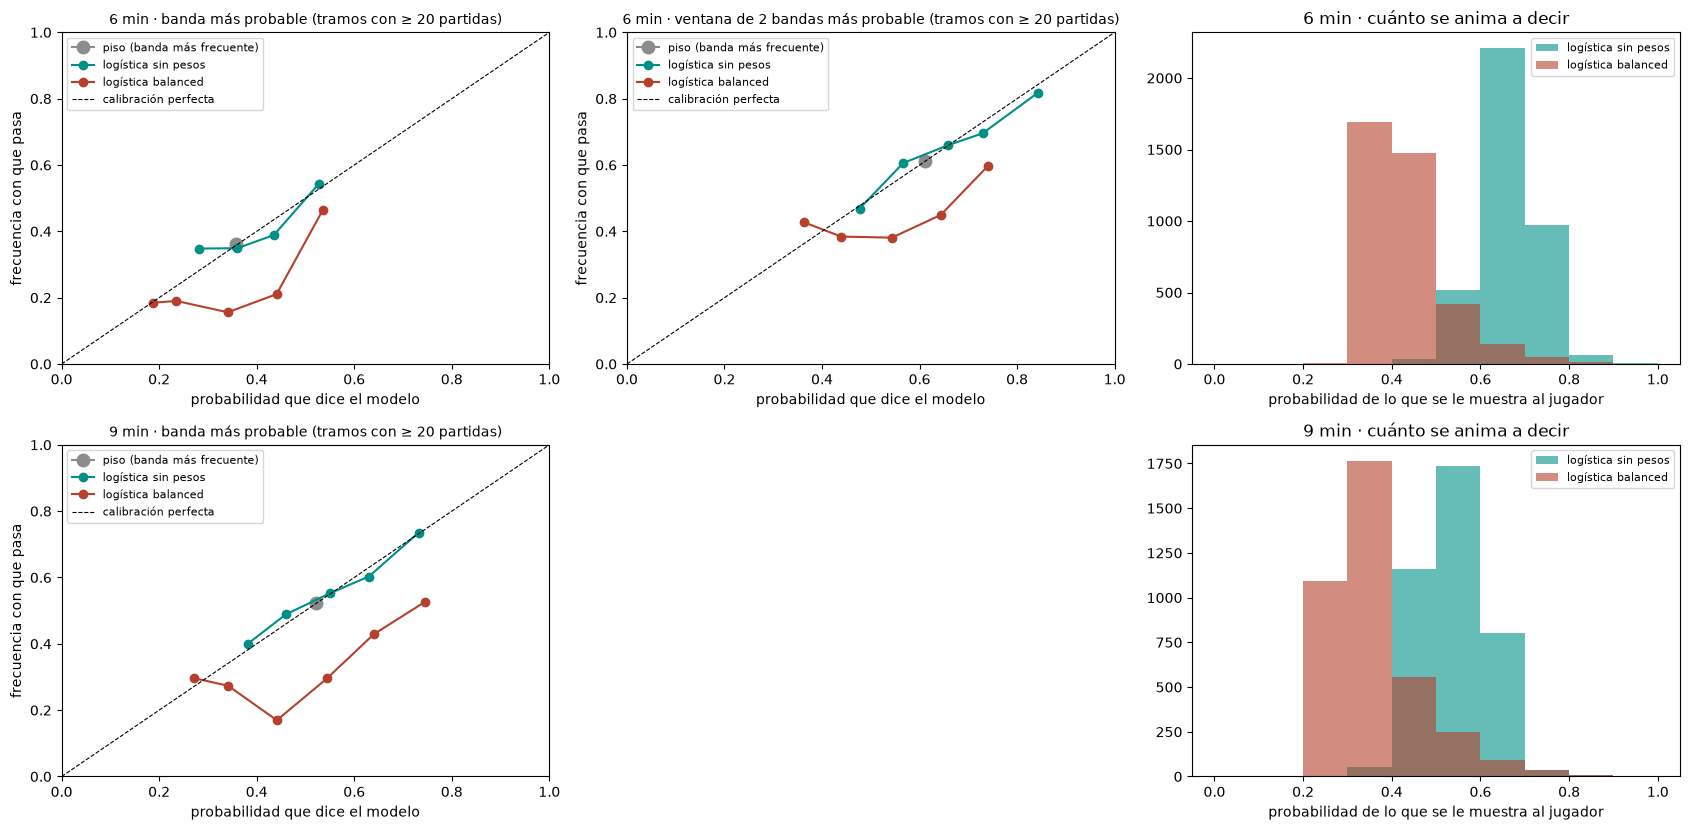

probabilidad media que dice  frecuencia con que pasa
6 min piso (banda más frecuente) banda más probable                                      0.358                    0.362
                                 ventana de 2 bandas más probable                        0.610                    0.612
      logística sin pesos        banda más probable                                      0.390                    0.369
                                 ventana de 2 bandas más probable                        0.666                    0.663
      logística balanced         banda más probable                                      0.244                    0.189
                                 ventana de 2 bandas más probable                        0.429                    0.409
9 min piso (banda más frecuente) banda más probable                                      0.521                    0.522
      logística sin pesos        banda más probable                                      0.539                    0.544
      logística balanced         banda más probable                                      0.362                    0.273

In [16]:
# 5.3 · La calibración: cuando el modelo dice «p %», ¿pasa el p % de las veces?
# Se mide sobre la banda más probable y, con 6 min, también sobre la ventana de 2 bandas que se le muestra al jugador
cortes = np.linspace(0, 1, 11)
calibracion, resolucion, al_jugador = {}, {}, {}
fig, axes = plt.subplots(2, 3, figsize=(17, 8.4))
for fila, (ancho, a) in zip(axes, ANCHOS.items()):
    real = a["yb_te"].to_numpy()
    casos_por_modelo = {}
    for n, P in proba[ancho].items():
        P = P.to_numpy()
        casos = {"banda más probable": (P.max(axis=1), P.argmax(axis=1) == real)}
        if a["ventana"] > 1:
            s = sumas_ventana(P, a["ventana"])
            inicio = s.argmax(axis=1)
            casos[f"ventana de {a['ventana']} bandas más probable"] = (
                s.max(axis=1), (real >= inicio) & (real <= inicio + a["ventana"] - 1))
        casos_por_modelo[n] = casos
        for ax, (caso, (dice, acierta)) in zip(fila[:2], casos.items()):
            c = pd.DataFrame({"dice": dice, "acierta": acierta}).groupby(pd.cut(dice, cortes), observed=True).agg(
                dice=("dice", "mean"), pasa=("acierta", "mean"), partidas=("acierta", "size"))
            c = c[c["partidas"] >= 20]
            ax.plot(c["dice"], c["pasa"], marker="o", markersize=9 if n == PISO else 6, color=COLOR[n], label=n)
            calibracion[(ancho, n, caso)] = {"probabilidad media que dice": dice.mean(),
                                             "frecuencia con que pasa": acierta.mean()}
        # Lo que se le muestra al jugador es el último caso: la ventana con 6 min, la banda con 9
        al_jugador[(ancho, n)] = list(casos.values())[-1]
    for ax, caso in zip(fila[:2], casos):
        ax.plot([0, 1], [0, 1], color="black", linestyle="--", linewidth=0.8, label="calibración perfecta")
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.set_xlabel("probabilidad que dice el modelo")
        ax.set_ylabel("frecuencia con que pasa")
        ax.set_title(f"{ancho} · {caso} (tramos con ≥ 20 partidas)", fontsize=10)
        ax.legend(fontsize=8)
    if len(casos) == 1:
        fila[1].axis("off")
    for n in modelos[ancho]:
        fila[2].hist(al_jugador[(ancho, n)][0], bins=cortes, color=COLOR[n], alpha=0.6, label=n)
    fila[2].set_xlabel("probabilidad de lo que se le muestra al jugador")
    fila[2].set_title(f"{ancho} · cuánto se anima a decir")
    fila[2].legend(fontsize=8)
plt.tight_layout()
plt.show()
pd.DataFrame(calibracion).T.round(3)

**Las probabilidades de la sin pesos son creíbles, con los dos anchos.**

- **6 minutos**: para la ventana de 2 bandas que vería el jugador dice en promedio
  **66,6 %** y pasa el **66,3 %** de las veces, y la curva sigue la diagonal. Para la banda
  sola exagera un poco: dice 39,0 % y pasa el 36,9 %.
- **9 minutos**: para la banda más probable, que es lo que vería el jugador, dice
  **53,9 %** y pasa el **54,4 %**, y la curva sigue la diagonal entre el 38 y el 73 %.

**La balanced está mal calibrada**: con 9 minutos dice 36,2 % y pasa el 27,3 %; con 6, para la
banda, dice 24,4 % y pasa el 18,9 %. Es un efecto conocido de los pesos: cambian para qué
lado se inclina el modelo, y con eso las probabilidades dejan de ser frecuencias.

**El piso también está calibrado**, pero dice siempre lo mismo: 61 % para la ventana `21-33`
con 6 minutos, y 52 % para `24-33` con 9, en todas las partidas. Una probabilidad calibrada
sirve si **cambia de partida en partida**, y eso es lo que mide la tabla de resolución.

In [17]:
# La resolución: si el modelo distingue las partidas en las que puede estar más seguro.
# Las partidas se parten en tercios según la probabilidad que el modelo le da a lo que se le muestra al jugador
for (ancho, n), (dice, acierta) in al_jugador.items():
    if n == PISO:
        continue
    tercio = pd.qcut(dice, 3, labels=["el tercio que dice menos", "el tercio del medio", "el tercio que dice más"])
    for nombre in tercio.categories:
        sel = np.asarray(tercio == nombre)
        resolucion[(ancho, n, nombre)] = {"probabilidad mínima": dice[sel].min(), "probabilidad máxima": dice[sel].max(),
                                          "probabilidad media que dice": dice[sel].mean(),
                                          "frecuencia con que pasa": acierta[sel].mean()}
pd.DataFrame(resolucion).T.round(3)

probabilidad mínima  probabilidad máxima  probabilidad media que dice  frecuencia con que pasa
6 min logística sin pesos el tercio que dice menos                0.437                0.644                        0.598                    0.600
                          el tercio del medio                     0.645                0.691                        0.669                    0.679
                          el tercio que dice más                  0.691                0.961                        0.730                    0.709
      logística balanced  el tercio que dice menos                0.289                0.383                        0.353                    0.406
                          el tercio del medio                     0.383                0.439                        0.409                    0.427
                          el tercio que dice más                  0.439                0.904                        0.526                    0.393
9 min logística sin pesos el tercio que dice menos                0.313                0.503                        0.458                    0.483
                          el tercio del medio                     0.503                0.577                        0.540                    0.542
                          el tercio que dice más                  0.577                0.880                        0.620                    0.606
      logística balanced  el tercio que dice menos                0.211                0.307                        0.276                    0.294
                          el tercio del medio                     0.307                0.370                        0.335                    0.294
                          el tercio que dice más                  0.371                0.910                        0.473                    0.232

**La sin pesos distingue partidas en las que puede estar más segura.** Las partidas se
parten en tercios según lo que el modelo dice para lo que vería el jugador:

- **6 minutos** (ventana de 12 minutos): en el tercio en que dice menos (entre 44 y 64 %)
  acierta el **60,0 %**; en el tercio en que dice más (69 % o más), el **70,9 %**.
- **9 minutos** (banda de 9 minutos): en el tercio en que dice menos (entre 31 y 50 %)
  acierta el **48,3 %**; en el que dice más (58 % o más), el **60,6 %**.

El piso dice siempre lo mismo (61 % y 52 %). La diferencia no es grande, unos 11 y 12
puntos, pero es real, está calibrada, y es lo único que la logística le da al jugador que
el piso no le da. **La balanced no tiene resolución**: con 9 minutos, en el tercio en que
dice más, acierta *menos* (23,2 %) que en el que dice menos (29,4 %).

# Sección 6 · Qué aprendió

Como en la Práctica 1 (5.1 y 5.4): los coeficientes de la logística, que dicen qué
empuja hacia cada banda, y la importancia por permutación, que dice qué columnas
necesita el modelo.

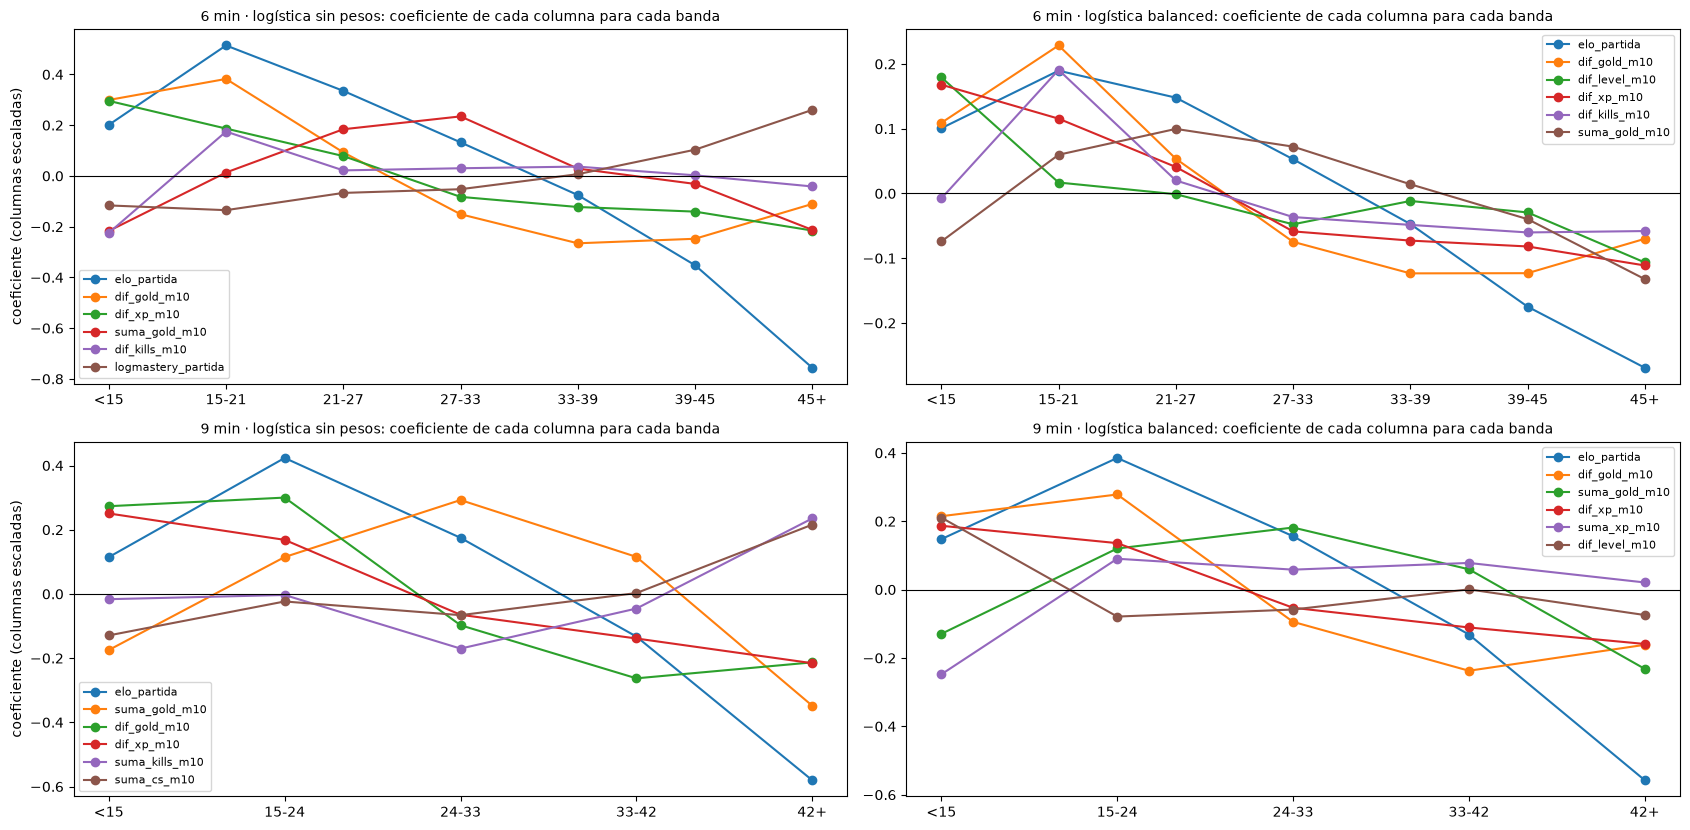

<15  15-21  21-27  27-33  33-39  39-45   45+  15-24  24-33  33-42   42+
6 min elo_partida   0.20   0.51   0.34   0.13  -0.08  -0.35 -0.76    NaN    NaN    NaN   NaN
      dif_gold_m10  0.30   0.38   0.09  -0.15  -0.27  -0.25 -0.11    NaN    NaN    NaN   NaN
9 min elo_partida   0.11    NaN    NaN    NaN    NaN    NaN   NaN   0.42   0.17  -0.13 -0.58
      dif_gold_m10  0.27    NaN    NaN    NaN    NaN    NaN   NaN   0.30  -0.10  -0.26 -0.21

In [18]:
# 6.1 · Los coeficientes: una curva por columna numérica, a lo largo de las bandas (las seis que más se mueven)
fig, axes = plt.subplots(2, 2, figsize=(17, 8.4))
coeficientes = {}
for fila, (ancho, a) in zip(axes, ANCHOS.items()):
    for ax, (n, m) in zip(fila, modelos[ancho].items()):
        coef = pd.DataFrame(m[-1].coef_, index=a["bandas"], columns=m[:-1].get_feature_names_out())
        coef = coef.loc[:, ~coef.columns.str.startswith("plataforma_")]  # la plataforma, en 6.2
        coeficientes[(ancho, n)] = coef
        top6 = (coef.max() - coef.min()).sort_values(ascending=False).head(6).index
        for c in top6:
            ax.plot(a["bandas"], coef[c], marker="o", label=c)
        ax.axhline(0, color="black", linewidth=0.8)
        ax.set_title(f"{ancho} · {n}: coeficiente de cada columna para cada banda", fontsize=10)
        ax.legend(fontsize=8)
    fila[0].set_ylabel("coeficiente (columnas escaladas)")
plt.tight_layout()
plt.show()
pd.concat({ancho: coeficientes[(ancho, final[ancho])][["elo_partida", "dif_gold_m10"]].T for ancho in ANCHOS}).round(2)

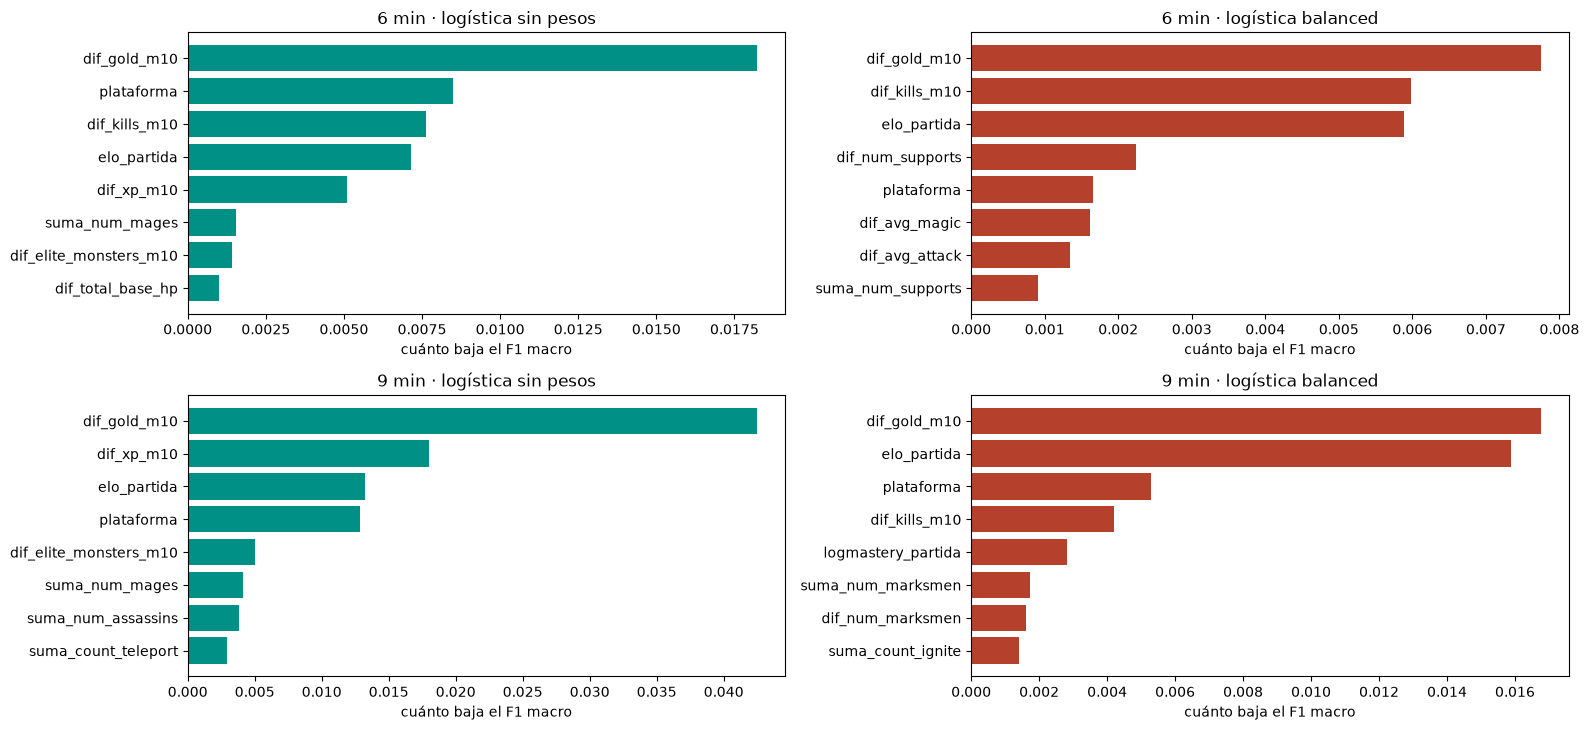

logística sin pesos  logística balanced
6 min dif_gold_m10                         0.0182              0.0077
      plataforma                           0.0085              0.0017
      dif_kills_m10                        0.0076              0.0060
      elo_partida                          0.0071              0.0059
      dif_xp_m10                           0.0051              0.0003
      suma_num_mages                       0.0016             -0.0022
9 min dif_gold_m10                         0.0425              0.0168
      dif_xp_m10                           0.0180             -0.0000
      elo_partida                          0.0132              0.0159
      plataforma                           0.0129              0.0053
      dif_elite_monsters_m10               0.0051             -0.0038
      suma_num_mages                       0.0042             -0.0002

In [19]:
# 6.2 · La importancia por permutación en el test: cuánto baja el F1 macro al desordenar cada columna derivada
fig, axes = plt.subplots(2, 2, figsize=(16, 7.4))
importancia = {}
for fila, (ancho, a) in zip(axes, ANCHOS.items()):
    for ax, (n, m) in zip(fila, modelos[ancho].items()):
        Z = m["derivar"].transform(X10_te)
        pi = permutation_importance(m[1:], Z, a["yb_te"], scoring="f1_macro", n_repeats=10,
                                    random_state=SEMILLA, n_jobs=-1)
        importancia[(ancho, n)] = pd.Series(pi.importances_mean, index=Z.columns)
        top = importancia[(ancho, n)].sort_values().tail(8)
        ax.barh(top.index, top, color=COLOR[n])
        ax.set_title(f"{ancho} · {n}")
        ax.set_xlabel("cuánto baja el F1 macro")
plt.tight_layout()
plt.show()
pd.concat({ancho: pd.DataFrame({n: importancia[(ancho, n)] for n in modelos[ancho]})
                  .sort_values(final[ancho], ascending=False).head(6) for ancho in ANCHOS}).round(4)

**Qué empuja hacia las bandas cortas y largas.** Los coeficientes de la sin pesos cuentan lo
mismo con los dos anchos, y lo mismo que la Entrega 3:

- **`elo_partida`** baja de **+0,51** en `15-21` a **−0,76** en `45+` (6 minutos), y de +0,42 en
  `15-24` a −0,58 en `42+` (9 minutos): a más elo, partidas más cortas.
- **`dif_gold_m10`**, la diferencia de oro al minuto 10, es **+0,38** en `15-21` y baja a
  −0,27 en `33-39` (6 minutos), y de +0,30 en `15-24` a −0,26 en `33-42` (9 minutos): un
  equipo que ya se separó cierra rápido. Es lo que afirmaba H9, y explica la banda de la
  rendición.
- Las curvas zigzaguean en `<15`: tiene 104 partidas de entrenamiento, y sus coeficientes se
  estiman con poco. Se lee la tendencia, no cada punto.

**La permutación lo confirma.** Para la sin pesos, la que más pesa es **`dif_gold_m10`** en
los dos anchos: desordenarla baja el F1 macro en 0,018 con 6 minutos (un 11 % de su valor)
y en 0,043 con 9 (un 19 %). Con 6 minutos siguen la plataforma (0,009), `dif_kills_m10`
(0,008) y el elo (0,007). Con 9, `dif_xp_m10` (0,018), el elo y la plataforma (0,013 cada una).

# Sección 7 · El MSE y el R², con el gráfico

El docente pidió probar el MSE y expresar bien el R². Son métricas de regresión: se
calculan sobre una predicción en números. Primero, sobre el modelo de la Entrega 3,
`Ridge(alpha=100)`, con las mismas columnas y el mismo test. Después, sobre los dos
clasificadores finales, **pasando cada banda predicha a minutos** con el minuto típico
de la banda (la mediana de sus partidas de entrenamiento, el mismo de la Sección 3).

In [20]:
ridge = armar(Ridge(alpha=100)).fit(X10, y10)
pr = ridge.predict(X10_te)
varianza = ((y10_te - y10_te.mean()) ** 2).mean()
mse = mean_squared_error(y10_te, pr)
pd.Series({"MAE (s)": mean_absolute_error(y10_te, pr), "MSE (s²)": mse, "RMSE (s)": np.sqrt(mse),
           "varianza de lo real (s²)": varianza, "1 − MSE / varianza": 1 - mse / varianza,
           "R² (r2_score)": r2_score(y10_te, pr)}).round(3)

MAE (s)                        294.679
MSE (s²)                    144081.971
RMSE (s)                       379.581
varianza de lo real (s²)    165425.591
1 − MSE / varianza               0.129
R² (r2_score)                    0.129
dtype: float64

**El R² es 1 − MSE / varianza.** La varianza de la duración real en el test es
165.426 s²: es el error cuadrático de contestar siempre el promedio. La regresión de la
E3 tiene un MSE de 144.082 s², el 87,1 % de eso. Lo que se saca de encima, el
**12,9 %**, es el R² de 0,129. **No es un porcentaje de partidas acertadas**: es cuánto
baja el error cuadrático respecto del promedio.

**El MSE eleva los errores al cuadrado**, así que castiga más los errores grandes y se
mide en segundos². Su raíz, el **RMSE**, vuelve a segundos: 379,6, contra un MAE de
294,7. Que el RMSE supere al MAE dice que hay errores grandes que pesan.

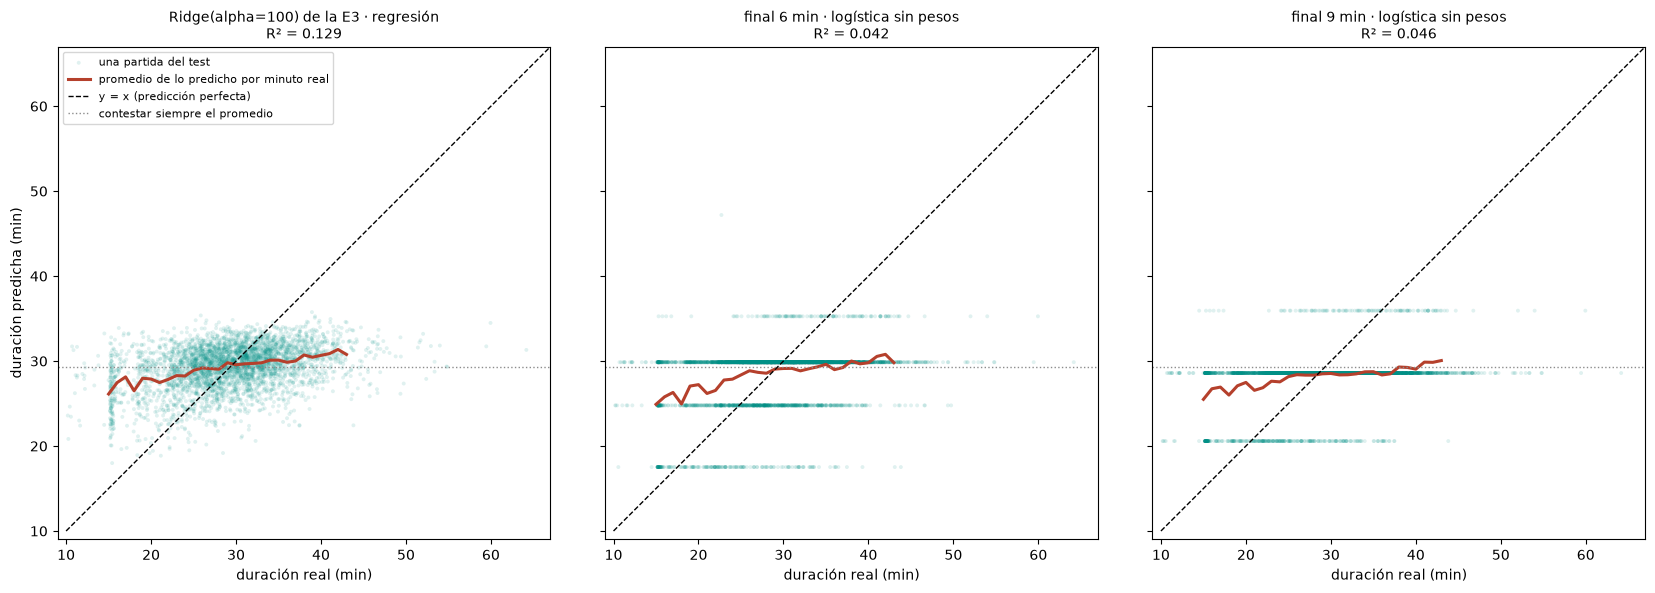

,R²,MSE (min²),RMSE (min),MAE (min),varianza de lo real (min²),valores distintos que predice
Ridge(alpha=100) de la E3 · regresión,0.129,40.023,6.326,4.911,45.952,3798.0
final 6 min · logística sin pesos,0.042,43.999,6.633,5.145,45.952,5.0
final 9 min · logística sin pesos,0.046,43.859,6.623,5.151,45.952,3.0


In [21]:
# 7.2 · Lo predicho contra lo real: cuánto se parecen las predicciones a la recta y = x
real_min = y10_te / 60
paneles = {"Ridge(alpha=100) de la E3 · regresión": pd.Series(pr / 60, index=te)} | \
          {f"final {ancho} · {final[ancho]}": pd.Series(ANCHOS[ancho]["minuto"][pred[ancho][final[ancho]]], index=te)
           for ancho in ANCHOS}
tramo = real_min.round()  # para el promedio de lo predicho en cada minuto real
r2 = {}
fig, axes = plt.subplots(1, 3, figsize=(17, 5.6), sharex=True, sharey=True)
for ax, (n, p) in zip(axes, paneles.items()):
    mse_min = mean_squared_error(real_min, p)
    r2[n] = {"R²": r2_score(real_min, p), "MSE (min²)": mse_min, "RMSE (min)": np.sqrt(mse_min),
             "MAE (min)": mean_absolute_error(real_min, p), "varianza de lo real (min²)": real_min.var(ddof=0),
             "valores distintos que predice": p.nunique()}
    ax.scatter(real_min, p, s=8, alpha=0.12, color=TEAL, edgecolors="none", label="una partida del test")
    medio = p.groupby(tramo).agg(["mean", "size"])
    medio = medio[medio["size"] >= 20]
    ax.plot(medio.index, medio["mean"], color=LADRILLO, linewidth=2.2, label="promedio de lo predicho por minuto real")
    ax.plot([10, 67], [10, 67], color="black", linestyle="--", linewidth=1, label="y = x (predicción perfecta)")
    ax.axhline(real_min.mean(), color=GRIS, linestyle=":", linewidth=1, label="contestar siempre el promedio")
    ax.set_title(f"{n}\nR² = {r2[n]['R²']:.3f}", fontsize=10)
    ax.set_xlabel("duración real (min)")
    ax.set_xlim(9, 67)
    ax.set_ylim(9, 67)
    ax.set_aspect("equal")
axes[0].set_ylabel("duración predicha (min)")
axes[0].legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()
pd.DataFrame(r2).T.round(3)

**Cómo se lee el gráfico.** Cada punto es una partida del test: en el eje x, lo que duró;
en el y, lo que predijo el modelo. Si las predicciones fueran perfectas, todos los puntos
caerían sobre la **recta y = x** (la diagonal punteada). Contestar siempre el promedio es la
línea horizontal gris: ahí el R² es 0. La **línea roja** es el promedio de lo predicho para
cada minuto real. Cuanto más se parece a la diagonal, más se parecen las predicciones a lo
real. Cuanto más se acuesta, más se pegan al promedio.

- **Ridge de la E3, R² = 0,129.** Las predicciones quedan entre unos 18 y 36 minutos, y la
  línea roja sube de unos 26 a unos 31 minutos mientras lo real va de 15 a 43: es mucho más
  plana que la diagonal. La franja vertical en el minuto 15 son las rendiciones, que el
  modelo predice a lo largo de todo el rango.
- **Final de 6 minutos, R² = 0,042.** Pasado a minutos, el clasificador sólo puede contestar
  el minuto típico de las bandas que predice, así que los puntos forman **rayas
  horizontales**: cinco valores distintos (17,5, 24,8, 29,9, 35,3 y una vez 47,2). La línea
  roja es todavía más plana que la del Ridge.
- **Final de 9 minutos, R² = 0,046.** Tres rayas (20,6, 28,6 y 35,9 minutos), porque nunca
  contesta `<15` ni `42+`.

**En números**: el MSE de los dos clasificadores, pasado a minutos, es 44,0 y 43,9 min²,
contra una varianza de 45,95 min²: bajan el error cuadrático un **4 y un 5 %** respecto de contestar
siempre el promedio. El Ridge lo baja un 12,9 %. Que el clasificador quede abajo es
esperable: al pasar de una banda a su minuto típico se pierde todo lo que el modelo sabe
adentro de la banda. **Las tres líneas rojas son mucho más planas que la diagonal**: con lo
que se sabe al minuto 10, ningún modelo separa bien una partida de 20 minutos de una de 40.

**Con la clasificación, el R² y el MSE no son la métrica con la que se elige**: el modelo
contesta una banda, no un número de minutos, y para calcularlos hay que inventarle un
número a cada banda. Se muestran porque los pidió el docente. Lo que cumple su función es
el F1 macro, el error en minutos de la Sección 3 y la calibración de la Sección 5.

# Sección 8 · Cierre

In [22]:
# La tabla que resume, sobre el mismo test: el piso y el modelo final de cada ancho
cierre = {}
for ancho in ANCHOS:
    for n in [PISO, final[ancho]]:
        cierre[(ancho, n)] = tabla[ancho].loc[n, ["C", "F1 macro cv", "desvío F1"]].to_dict() | \
                             test.loc[(ancho, n)].drop("error ≤ 5 min").to_dict()
    cierre[(ancho, final[ancho])]["R² (min)"] = r2[f"final {ancho} · {final[ancho]}"]["R²"]
pd.DataFrame(cierre).T.round(3)

C  F1 macro cv  desvío F1  F1 macro  accuracy  ±1 banda  error ≤ 3 min  error medio (min)  R² (min)
6 min piso (banda más frecuente)   NaN        0.075      0.001     0.076     0.362     0.820          0.365              5.306       NaN
      logística sin pesos         10.0        0.171      0.004     0.159     0.369     0.843          0.375              5.145     0.042
9 min piso (banda más frecuente)   NaN        0.137      0.000     0.137     0.522     0.964          0.370              5.321       NaN
      logística sin pesos          1.0        0.214      0.007     0.221     0.544     0.962          0.380              5.151     0.046

**Quedan dos modelos finales, los dos la regresión logística sin pesos**: uno con bandas de
6 minutos (`C=10`) y otro con bandas de 9 minutos (`C=1`). **La elección entre los dos es del
grupo.** Con 9 minutos, la regla de la cátedra elegía la balanced; el grupo la descartó
porque queda por debajo del piso en accuracy, en minutos y en calibración.

**Lo que tienen en común, sin adornarlo:**

- **Como clasificadores puros, apenas le ganan al piso de su ancho.** En F1 macro sí (0,159
  contra 0,076, y 0,221 contra 0,137), pero en accuracy ganan menos de dos puntos y medio, y en
  minutos dan casi lo mismo que el piso: 37,5 y 38,0 % de partidas a menos de 3 minutos,
  contra 36,5 y 37,0 %, con un error medio de 5,15 minutos en los dos.
- **Pasados a minutos, el R² es 0,042 y 0,046**, contra 0,129 de la regresión de la E3.
- **Lo que aportan son las probabilidades**: están calibradas y cambian de partida en partida.
- **Lo que miran** es la diferencia de oro al minuto 10, el elo de la partida y la plataforma.
  La única banda fuera del centro que ven venir es la corta, la de la rendición.

**En qué se diferencian** (la accuracy de uno no se compara con la del otro: la banda más
ancha la sube sola):

| | 6 minutos | 9 minutos |
|---|---|---|
| Lo que ve el jugador | ventana de 2 bandas (12 min) | la banda más probable (9 min) |
| Ejemplo (Sección 5.2) | «79 % de que termine entre los 21 y los 33» | «67 % de que termine entre los 24 y los 33» |
| Calibración de lo que ve | dice 66,6 %, pasa 66,3 % | dice 53,9 %, pasa 54,4 % |
| Resolución (tercio bajo → alto) | acierta del 60,0 al 70,9 % | acierta del 48,3 al 60,6 % |
| Bandas que llega a contestar | 5 de 7 | 3 de 5 |
| Variable que más pesa (permutación) | `dif_gold_m10`, 11 % del F1 | `dif_gold_m10`, 19 % del F1 |

**Para el jugador**, la salida no es una banda sola sino una frase con su probabilidad, que
hay que poder respaldar. Las probabilidades calibradas son lo que la respalda, con los dos
anchos. Con 6 minutos la frase cubre 12 minutos con más probabilidad; con 9 minutos cubre 9
minutos con menos.